# Data Preparation — Deeptech M&A Dataset

**Project**: Deeptech M&A Momentum — Building Alternative Investment Signals  
**Dataset**: All publicly announced M&A transactions > USD 50M since 2018 (global)  
**Source**: `trans50m_2k18.xlsx` (~38,655 transactions)

**This notebook covers**:
1. Data Loading & Cleaning
2. Quality Assessment
3. Descriptive Statistics & EDA
4. Text Preparation for LLM Sector Classification
5. Deep Analysis — Sector Classification, Networks, Correlations, Signals
6. Export Clean Dataset

## 1. Data Loading & Cleaning

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 80)

In [2]:
# Load the Excel file — row 0 in the file is a title row, row 1 has actual column names
df_raw = pd.read_excel("trans50m_2k18.xlsx", header=1)
print(f"Raw shape: {df_raw.shape}")
df_raw.columns.tolist()

Raw shape: (38655, 14)


['All Transactions Announced Date',
 'All Transactions Announced Date (Including Bids and Letters of Intent)',
 'Target/Issuer',
 'Exchange:Ticker',
 'Transaction Types',
 'Transaction Status',
 'Total Transaction Value ($USDmm, Historical rate)',
 'Buyers/Investors',
 'Sellers',
 'CIQ Transaction ID',
 'Transaction Comments',
 'Country/Region of Incorporation [Target/Issuer]',
 'Country/Region of Incorporation [Sellers]',
 'Target Security Types']

In [3]:
# Rename columns to shorter, code-friendly names
col_rename = {
    'All Transactions Announced Date': 'announced_date',
    'All Transactions Announced Date (Including Bids and Letters of Intent)': 'announced_date_incl_bids',
    'Target/Issuer': 'target',
    'Exchange:Ticker': 'ticker',
    'Transaction Types': 'transaction_type',
    'Transaction Status': 'status',
    'Total Transaction Value ($USDmm, Historical rate)': 'value_usd_mm',
    'Buyers/Investors': 'buyer',
    'Sellers': 'seller',
    'CIQ Transaction ID': 'transaction_id',
    'Transaction Comments': 'comments',
    'Country/Region of Incorporation [Target/Issuer]': 'target_country',
    'Country/Region of Incorporation [Sellers]': 'seller_country',
    'Target Security Types': 'security_type',
}
df = df_raw.rename(columns=col_rename).copy()

# Drop 'transaction_type' — all rows are "Merger/Acquisition"
assert df['transaction_type'].nunique() == 1, "Expected single transaction type"
df.drop(columns='transaction_type', inplace=True)

print(f"Columns after rename & drop: {df.columns.tolist()}")
print(f"Shape: {df.shape}")

Columns after rename & drop: ['announced_date', 'announced_date_incl_bids', 'target', 'ticker', 'status', 'value_usd_mm', 'buyer', 'seller', 'transaction_id', 'comments', 'target_country', 'seller_country', 'security_type']
Shape: (38655, 13)


In [4]:
# Replace '-' placeholders with NaN across all string columns
str_cols = df.select_dtypes(include='object').columns
df[str_cols] = df[str_cols].replace('-', np.nan)

# Convert dates to datetime
df['announced_date'] = pd.to_datetime(df['announced_date'], errors='coerce')
df['announced_date_incl_bids'] = pd.to_datetime(df['announced_date_incl_bids'], errors='coerce')

# Convert transaction value to float
df['value_usd_mm'] = pd.to_numeric(df['value_usd_mm'], errors='coerce')

print("Dtypes after conversion:")
print(df.dtypes)
print(f"\nDate range: {df['announced_date'].min()} to {df['announced_date'].max()}")
print(f"Value range: ${df['value_usd_mm'].min():.1f}M to ${df['value_usd_mm'].max():.1f}M")

Dtypes after conversion:
announced_date              datetime64[ns]
announced_date_incl_bids    datetime64[ns]
target                              object
ticker                              object
status                              object
value_usd_mm                       float64
buyer                               object
seller                              object
transaction_id                      object
comments                            object
target_country                      object
seller_country                      object
security_type                       object
dtype: object

Date range: 2018-01-02 00:00:00 to 2025-10-22 00:00:00
Value range: $50.0M to $103965.6M


In [5]:
# Quick preview of the cleaned data
df.head(3)

,announced_date,announced_date_incl_bids,target,ticker,status,value_usd_mm,buyer,seller,transaction_id,comments,target_country,seller_country,security_type
0,2021-05-17,2021-05-17,"Warner Media, LLC",NaN,Closed,103965.65,"Warner Bros. Discovery, Inc. (NasdaqGS:WBD)",AT&T Inc. (NYSE:T),IQTR715171572,"Discovery, Inc. (NasdaqGS:DISC.A) entered into a definitive agreement to acq...",United States,United States,Common Equity
1,2019-01-03,2019-01-02,Celgene Corporation,NaN,Closed,99553.55,Bristol-Myers Squibb Company (NYSE:BMY),NaN,IQTR597000614,Bristol-Myers Squibb Company (NYSE:BMY) entered into a definitive merger agr...,United States,NaN,Common Equity
2,2019-03-27,2019-03-27,Saudi Basic Industries Corporation (SASE:2010),SASE:2010,Closed,94221.44,Saudi Arabian Oil Company (SASE:2222),Public Investment Fund,IQTR607827179,Saudi Arabian Oil Company signed a share purchase agreement to acquire 70% s...,Saudi Arabia,United Arab Emirates,Common Equity


## 2. Quality Assessment

In [6]:
# Missing data report
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values('missing_pct', ascending=False)
missing[missing['missing_count'] > 0]

,missing_count,missing_pct
ticker,35739,92.46
target_country,17530,45.35
seller_country,14740,38.13
seller,10597,27.41
buyer,2201,5.69


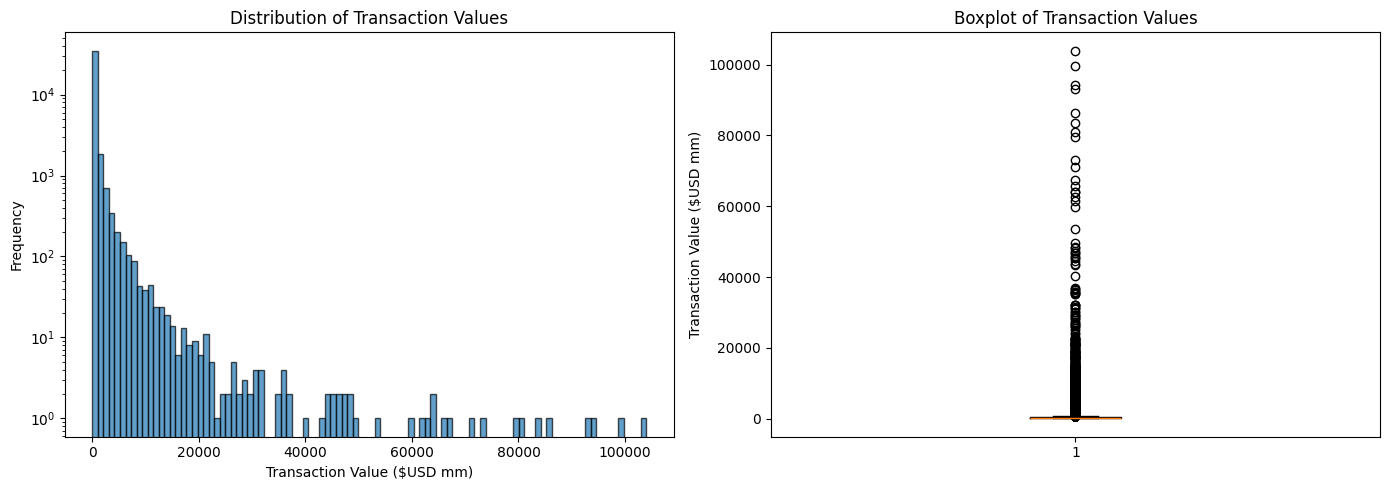

Q1: $82.0M | Q3: $373.4M | IQR: $291.3M
Upper fence: $810.4M | Outliers above fence: 4996 (12.9%)

Percentiles:
  50th: $150.0M
  75th: $373.4M
  90th: $1,058.2M
  95th: $2,121.0M
  99th: $7,622.6M


In [7]:
# Outlier analysis on transaction value
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram (log scale due to heavy right skew)
axes[0].hist(df['value_usd_mm'].dropna(), bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Transaction Value ($USD mm)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Transaction Values')
axes[0].set_yscale('log')

# Boxplot
axes[1].boxplot(df['value_usd_mm'].dropna(), vert=True)
axes[1].set_ylabel('Transaction Value ($USD mm)')
axes[1].set_title('Boxplot of Transaction Values')

plt.tight_layout()
plt.show()

# IQR analysis
Q1 = df['value_usd_mm'].quantile(0.25)
Q3 = df['value_usd_mm'].quantile(0.75)
IQR = Q3 - Q1
upper_fence = Q3 + 1.5 * IQR
n_outliers = (df['value_usd_mm'] > upper_fence).sum()
print(f"Q1: ${Q1:.1f}M | Q3: ${Q3:.1f}M | IQR: ${IQR:.1f}M")
print(f"Upper fence: ${upper_fence:.1f}M | Outliers above fence: {n_outliers} ({n_outliers/len(df)*100:.1f}%)")
print(f"\nPercentiles:")
for p in [50, 75, 90, 95, 99]:
    print(f"  {p}th: ${df['value_usd_mm'].quantile(p/100):,.1f}M")

In [8]:
# Consistency checks
print("=== Consistency Checks ===\n")

# 1. Date range validation
date_before_2018 = (df['announced_date'] < '2018-01-01').sum()
date_future = (df['announced_date'] > pd.Timestamp.now()).sum()
print(f"Dates before 2018: {date_before_2018}")
print(f"Dates in the future: {date_future}")

# 2. Value validation (all should be >= 50M per dataset description)
below_50m = (df['value_usd_mm'] < 50).sum()
print(f"Values below $50M: {below_50m}")

# 3. Duplicate transaction IDs
dup_ids = df['transaction_id'].duplicated().sum()
print(f"Duplicate transaction IDs: {dup_ids}")

# 4. Transaction status breakdown
print(f"\nTransaction status counts:")
print(df['status'].value_counts())

=== Consistency Checks ===

Dates before 2018: 0
Dates in the future: 0
Values below $50M: 0
Duplicate transaction IDs: 0

Transaction status counts:
status
Closed       34109
Announced     3780
Effective      766
Name: count, dtype: int64


In [9]:
# Data dictionary
data_dict = pd.DataFrame({
    'column': df.columns,
    'dtype': df.dtypes.values,
    'non_null': df.notnull().sum().values,
    'null_pct': (df.isnull().sum() / len(df) * 100).round(1).values,
    'n_unique': df.nunique().values,
    'sample_value': [df[col].dropna().iloc[0] if df[col].notnull().any() else np.nan for col in df.columns]
})
data_dict

,column,dtype,non_null,null_pct,n_unique,sample_value
0,announced_date,datetime64[ns],38655,0.0,2610,2021-05-17 00:00:00
1,announced_date_incl_bids,datetime64[ns],38655,0.0,2648,2021-05-17 00:00:00
2,target,object,38655,0.0,36790,"Warner Media, LLC"
3,ticker,object,2916,92.5,2284,SASE:2010
4,status,object,38655,0.0,3,Closed
5,value_usd_mm,float64,38655,0.0,20389,103965.65
6,buyer,object,36454,5.7,22649,"Warner Bros. Discovery, Inc. (NasdaqGS:WBD)"
7,seller,object,28058,27.4,20803,AT&T Inc. (NYSE:T)
8,transaction_id,object,38655,0.0,38655,IQTR715171572
9,comments,object,38655,0.0,38655,"Discovery, Inc. (NasdaqGS:DISC.A) entered into a definitive agreement to acq..."


## 3. Descriptive Statistics & EDA

In [10]:
# Numeric summary
print("=== Transaction Value Summary ===")
print(df['value_usd_mm'].describe().to_string())
print(f"\nTotal deal volume: ${df['value_usd_mm'].sum():,.0f}M")
print(f"Median deal size: ${df['value_usd_mm'].median():,.1f}M")

print("\n=== Categorical Summary ===")
print(f"Unique targets: {df['target'].nunique():,}")
print(f"Unique buyers: {df['buyer'].nunique():,}")
print(f"Unique sellers: {df['seller'].nunique():,}")
print(f"Unique target countries: {df['target_country'].nunique()}")
print(f"Security types: {df['security_type'].nunique()}")

=== Transaction Value Summary ===
count     38655.000000
mean        598.032863
std        2470.854095
min          50.000000
25%          82.030000
50%         150.000000
75%         373.365000
max      103965.650000

Total deal volume: $23,116,960M
Median deal size: $150.0M

=== Categorical Summary ===
Unique targets: 36,790
Unique buyers: 22,649
Unique sellers: 20,803
Unique target countries: 137
Security types: 35


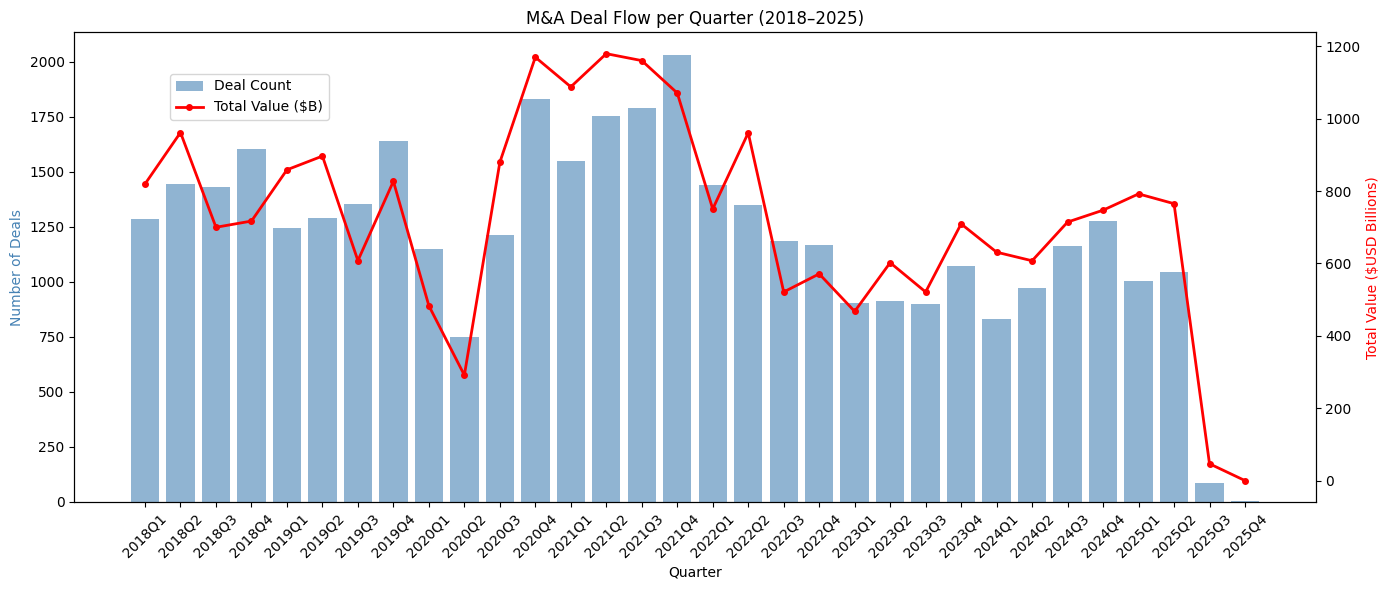

In [11]:
# Deals per quarter — this is the proto time-series for Step 2 of the project
df['quarter'] = df['announced_date'].dt.to_period('Q')
quarterly = df.groupby('quarter').agg(
    deal_count=('transaction_id', 'count'),
    total_value=('value_usd_mm', 'sum'),
    avg_value=('value_usd_mm', 'mean')
).reset_index()
quarterly['quarter_str'] = quarterly['quarter'].astype(str)

fig, ax1 = plt.subplots(figsize=(14, 6))

# Deal count bars
ax1.bar(quarterly['quarter_str'], quarterly['deal_count'], alpha=0.6, color='steelblue', label='Deal Count')
ax1.set_xlabel('Quarter')
ax1.set_ylabel('Number of Deals', color='steelblue')
ax1.tick_params(axis='x', rotation=45)

# Total value line on secondary axis
ax2 = ax1.twinx()
ax2.plot(quarterly['quarter_str'], quarterly['total_value'] / 1000, color='red', linewidth=2, marker='o', markersize=4, label='Total Value ($B)')
ax2.set_ylabel('Total Value ($USD Billions)', color='red')

plt.title('M&A Deal Flow per Quarter (2018–2025)')
fig.legend(loc='upper left', bbox_to_anchor=(0.12, 0.88))
plt.tight_layout()
plt.show()

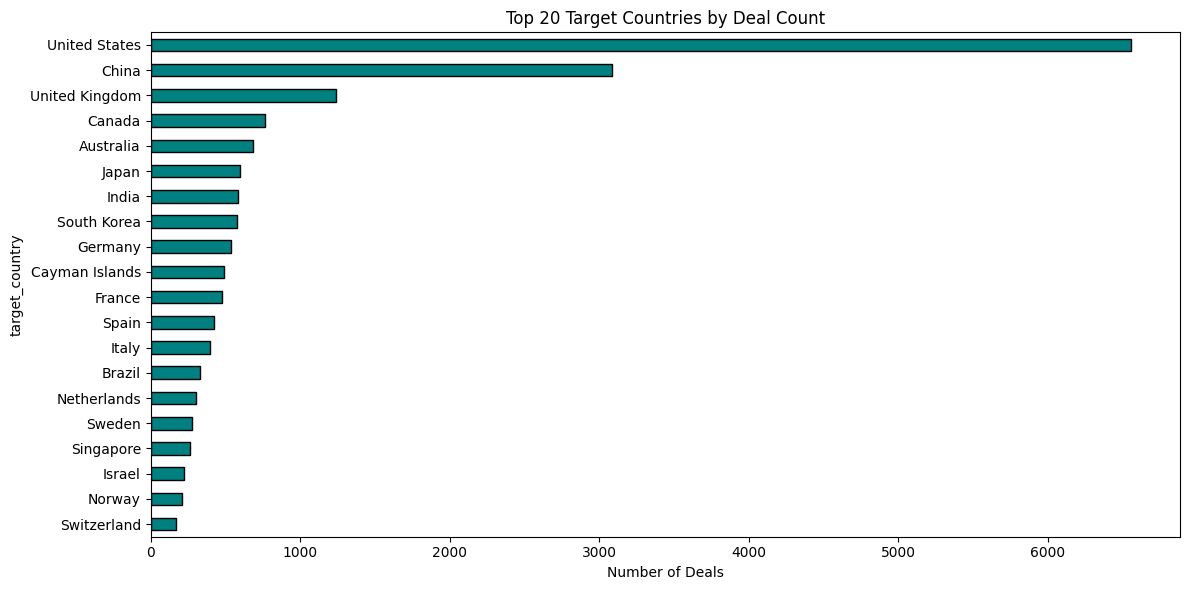

In [12]:
# Top 20 target countries
top_countries = df['target_country'].value_counts().head(20)

fig, ax = plt.subplots(figsize=(12, 6))
top_countries.plot(kind='barh', ax=ax, color='teal', edgecolor='black')
ax.set_xlabel('Number of Deals')
ax.set_title('Top 20 Target Countries by Deal Count')
ax.invert_yaxis()
plt.tight_layout()
plt.show()

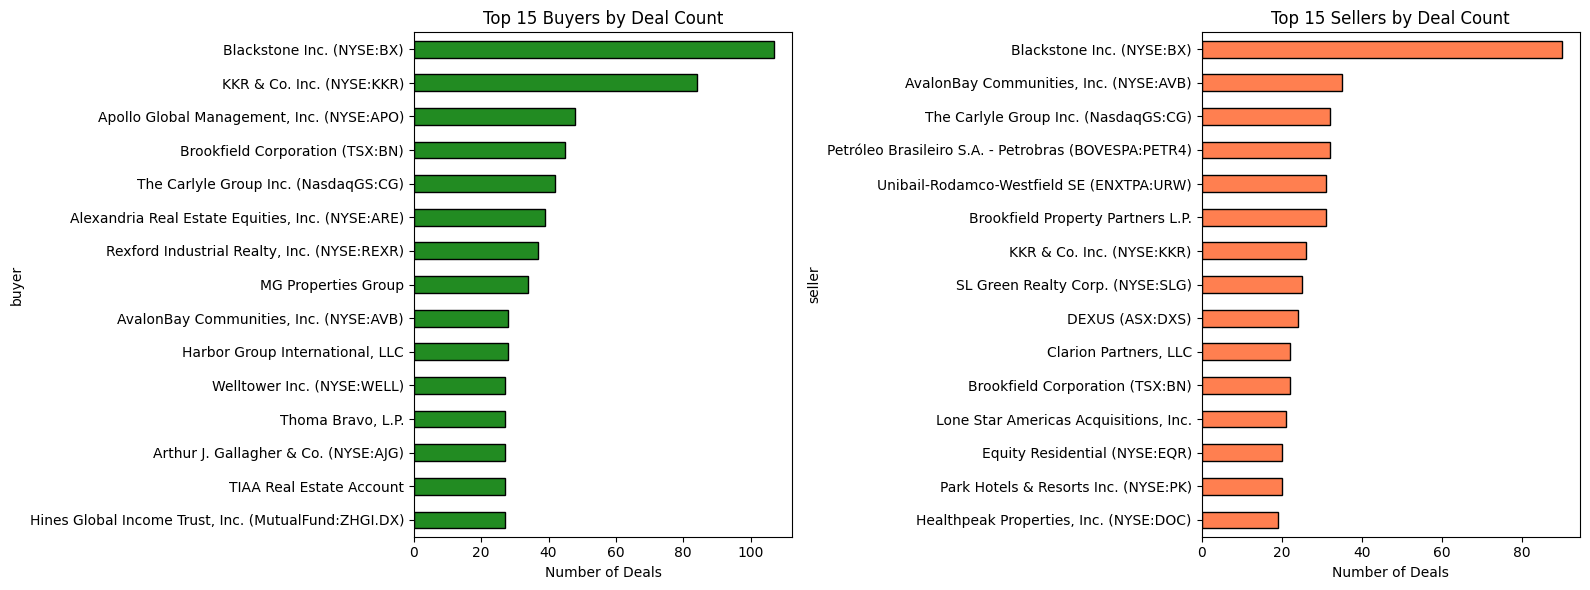


=== Security Type Breakdown ===
security_type
Common Equity                                                                                        22906
Asset                                                                                                14004
Common Equity; Rights / Warrants / Options                                                             641
Rights / Warrants / Options; Common Equity                                                             564
Common Equity; Hybrid Securities                                                                        94
Hybrid Securities; Common Equity                                                                        92
Preferred Equity (Non-Convertible); Common Equity                                                       88
Common Equity; Preferred Equity (Non-Convertible)                                                       82
Hybrid Securities; Common Equity; Rights / Warrants / Options                                    

In [13]:
# Top 15 repeat buyers and sellers
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df['buyer'].value_counts().head(15).plot(kind='barh', ax=axes[0], color='forestgreen', edgecolor='black')
axes[0].set_title('Top 15 Buyers by Deal Count')
axes[0].set_xlabel('Number of Deals')
axes[0].invert_yaxis()

df['seller'].value_counts().head(15).plot(kind='barh', ax=axes[1], color='coral', edgecolor='black')
axes[1].set_title('Top 15 Sellers by Deal Count')
axes[1].set_xlabel('Number of Deals')
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

# Security type breakdown
print("\n=== Security Type Breakdown ===")
print(df['security_type'].value_counts())

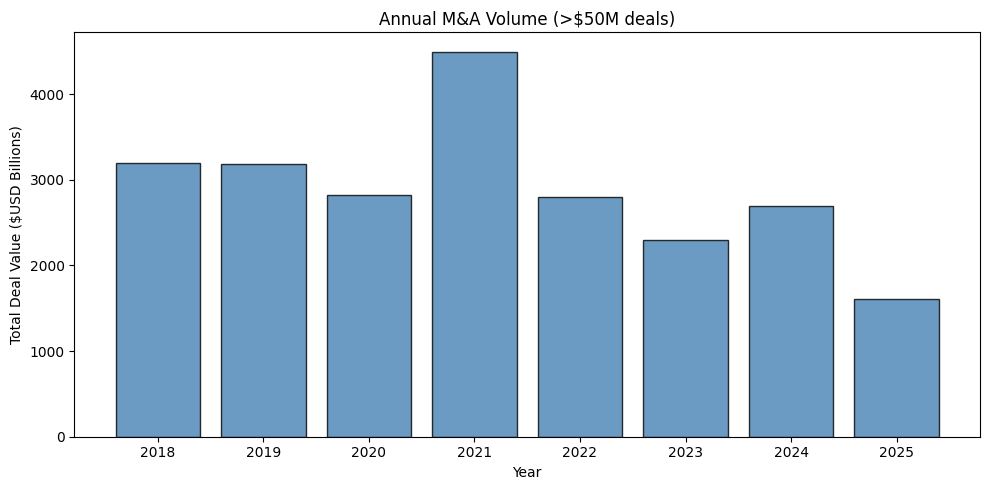

,total_value_mm,median_value_mm,deal_count
year,,,
2018,3197854.15,142.000,5759
2019,3189771.89,136.500,5525
2020,2823584.63,145.310,4945
2021,4497303.00,157.100,7120
2022,2803516.25,148.485,5140
2023,2300350.76,154.260,3787
2024,2699920.77,160.000,4241
2025,1604658.87,169.415,2138


In [14]:
# Deal value distribution by year
df['year'] = df['announced_date'].dt.year
yearly_value = df.groupby('year')['value_usd_mm'].agg(['sum', 'median', 'count'])
yearly_value.columns = ['total_value_mm', 'median_value_mm', 'deal_count']

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(yearly_value.index, yearly_value['total_value_mm'] / 1000, color='steelblue', edgecolor='black', alpha=0.8)
ax.set_xlabel('Year')
ax.set_ylabel('Total Deal Value ($USD Billions)')
ax.set_title('Annual M&A Volume (>$50M deals)')
plt.tight_layout()
plt.show()

yearly_value

## 4. Text Preparation for LLM Sector Classification

The project brief calls for LLM-based classification (e.g., Gemini 2.5 Pro) of transactions into deeptech sectors. Here we prepare the text input that will be sent to the LLM.

The key text fields are:
- **target**: Name of the target company (often contains sector hints)
- **comments**: Free-text deal description (richest source of sector info)
- **buyer**: Buyer name (may indicate acquiring sector)

In [15]:
# Create a combined text field for LLM classification input
# Explicit .astype(str) to handle columns with mixed types (some values are numeric/NaT)
df['llm_input_text'] = (
    "Target: " + df['target'].fillna('').astype(str) + " | " +
    "Buyer: " + df['buyer'].fillna('').astype(str) + " | " +
    "Deal: " + df['comments'].fillna('').astype(str)
)

# Preview a few examples
for i in range(3):
    print(f"--- Transaction {i+1} ---")
    print(f"Value: ${df.iloc[i]['value_usd_mm']:,.1f}M")
    print(f"Text: {df.iloc[i]['llm_input_text'][:300]}...")
    print()

--- Transaction 1 ---
Value: $103,965.6M
Text: Target: Warner Media, LLC | Buyer: Warner Bros. Discovery, Inc. (NasdaqGS:WBD) | Deal: Discovery, Inc. (NasdaqGS:DISC.A) entered into a definitive agreement to acquire Warner Media, LLC from AT&T Inc. (NYSE:T) for $60.6 billion on May 17, 2021. The transaction is structured as a reverse morris trust...

--- Transaction 2 ---
Value: $99,553.6M
Text: Target: Celgene Corporation | Buyer: Bristol-Myers Squibb Company (NYSE:BMY) | Deal: Bristol-Myers Squibb Company (NYSE:BMY) entered into a definitive merger agreement to acquire Celgene Corporation (NasdaqGS:CELG) for $73 billion on January 2, 2019. Under the terms of the agreement, Celgene shareho...

--- Transaction 3 ---
Value: $94,221.4M
Text: Target: Saudi Basic Industries Corporation (SASE:2010) | Buyer: Saudi Arabian Oil Company (SASE:2222) | Deal: Saudi Arabian Oil Company signed a share purchase agreement to acquire 70% stake in Saudi Basic Industries Corporation (SASE:2010) from Publi

In [16]:
# Text length statistics — useful for estimating LLM token costs
text_lengths = df['llm_input_text'].str.len()
print(f"LLM input text length stats:")
print(f"  Mean: {text_lengths.mean():.0f} chars")
print(f"  Median: {text_lengths.median():.0f} chars")
print(f"  Max: {text_lengths.max():.0f} chars")
print(f"  Approx total tokens (chars/4): {text_lengths.sum() / 4:,.0f}")

# Check for rows with very short text (may lack info for classification)
short_text = (text_lengths < 50).sum()
print(f"\nRows with < 50 chars of text: {short_text}")

LLM input text length stats:
  Mean: 1380 chars
  Median: 845 chars
  Max: 8126 chars
  Approx total tokens (chars/4): 13,333,216

Rows with < 50 chars of text: 0


## 5. Visual Intelligence — Sector Classification, Network & Capital Flow Analysis

### 5.0 Preliminary Sector Classification (Keyword-based)
Before the LLM-based classification (Step 1 of the brief), we apply a **keyword-based heuristic** to assign each transaction a preliminary sector. This enables sector-aware visualizations and provides a baseline for the LLM taxonomy to improve upon.

In [17]:
import re

# Sector taxonomy with keyword patterns (regex, case-insensitive)
# Word boundaries (\b) used for short keywords to avoid false positives
SECTOR_KEYWORDS = {
    'Quantum Computing': [r'quantum', r'qubit', r'quantum comput'],
    'AI & Machine Learning': [r'\bai\b', r'artificial intelligence', r'machine learning', r'deep learning',
                               r'neural network', r'generative ai', r'\bllm\b', r'computer vision',
                               r'natural language processing', r'\bnlp\b'],
    'Semiconductors & Chips': [r'semiconductor', r'\bchip\b', r'\bwafer\b', r'foundry', r'integrated circuit',
                                r'fabless', r'\basic\b', r'\bfpga\b', r'lithograph', r'etching'],
    'Cybersecurity': [r'cybersecurity', r'cyber security', r'information security', r'threat detection',
                      r'encryption', r'firewall', r'endpoint security', r'identity management'],
    'Aerospace & Defense': [r'aerospace', r'defense\b', r'defence\b', r'military', r'missile', r'\bradar\b',
                            r'satellite', r'space launch', r'unmanned aerial', r'fighter jet', r'naval'],
    'Robotics & Automation': [r'robot', r'automation', r'autonomous', r'\bdrone', r'unmanned vehicle',
                               r'industrial automation', r'cobot', r'lidar'],
    'Biotech & Pharma': [r'biotech', r'biotechnology', r'pharmaceutical', r'pharma\b', r'drug discovery',
                          r'gene therapy', r'genomic', r'biologic', r'oncolog', r'therapeutic',
                          r'clinical trial', r'biopharm', r'vaccine', r'antibod'],
    'Advanced Materials': [r'advanced material', r'nanomaterial', r'graphene', r'metamaterial',
                           r'ceramic', r'polymer', r'carbon fiber'],
    'Clean Energy & EV': [r'solar', r'wind energy', r'wind farm', r'renewable', r'clean energy',
                          r'battery', r'energy storage', r'hydrogen', r'fuel cell',
                          r'electric vehicle', r'\bev\b', r'charging station'],
    'Fintech': [r'fintech', r'payment processing', r'blockchain', r'cryptocurrency', r'crypto\b',
                r'digital banking', r'insurtech', r'neobank', r'defi\b'],
    'Healthcare & Medtech': [r'medical device', r'medtech', r'health tech', r'diagnostic',
                              r'medical imaging', r'telemedicine', r'digital health', r'surgical',
                              r'implant', r'prosthetic'],
    'Software & Cloud': [r'\bsaas\b', r'cloud computing', r'\bcloud\b', r'data analytics',
                         r'enterprise software', r'\berp\b', r'\bcrm\b', r'devops'],
    'Telecom & 5G': [r'telecom', r'\b5g\b', r'wireless network', r'fiber optic',
                     r'network infrastructure', r'broadband', r'mobile operator'],
    'Real Estate': [r'real estate', r'property', r'reit\b', r'residential', r'commercial property',
                    r'hotel', r'resort', r'housing'],
    'Oil & Gas': [r'oil\b', r'\bgas\b', r'petroleum', r'refinery', r'pipeline', r'upstream',
                  r'downstream', r'lng\b', r'drilling'],
    'Mining & Metals': [r'mining', r'\bgold\b', r'copper', r'lithium', r'iron ore', r'mineral',
                        r'steel', r'smelting'],
    'Financial Services': [r'bank\b', r'banking', r'insurance', r'asset management', r'wealth management',
                           r'brokerage', r'private equity', r'investment management', r'lending'],
    'Consumer & Retail': [r'consumer', r'retail', r'e-commerce', r'ecommerce', r'brand',
                          r'food\b', r'beverage', r'apparel', r'luxury'],
}

def classify_sector(text):
    """Classify a transaction into a sector based on keyword matching."""
    if pd.isna(text) or text is None:
        return 'Unclassified'
    text_lower = str(text).lower()
    for sector, patterns in SECTOR_KEYWORDS.items():
        for pattern in patterns:
            if re.search(pattern, text_lower):
                return sector
    return 'Unclassified'

# Classify using the combined LLM input text (target + buyer + comments)
df['sector'] = df['llm_input_text'].apply(classify_sector)

# Summary
sector_counts = df['sector'].value_counts()
print(f"Sector classification results ({len(SECTOR_KEYWORDS)} sectors + Unclassified):\n")
for sector, count in sector_counts.items():
    pct = count / len(df) * 100
    print(f"  {sector:30s} {count:6,} deals ({pct:5.1f}%)")

classified_pct = (1 - sector_counts.get('Unclassified', 0) / len(df)) * 100
print(f"\nClassified: {classified_pct:.1f}% of all transactions")
print(f"(Unclassified deals will be refined by LLM in the next notebook)")

Sector classification results (18 sectors + Unclassified):

  Unclassified                   17,173 deals ( 44.4%)
  Real Estate                     8,009 deals ( 20.7%)
  Financial Services              5,922 deals ( 15.3%)
  Consumer & Retail               1,476 deals (  3.8%)
  Oil & Gas                       1,217 deals (  3.1%)
  Biotech & Pharma                1,164 deals (  3.0%)
  Mining & Metals                 1,009 deals (  2.6%)
  Clean Energy & EV                 933 deals (  2.4%)
  Aerospace & Defense               370 deals (  1.0%)
  Telecom & 5G                      320 deals (  0.8%)
  Semiconductors & Chips            276 deals (  0.7%)
  Healthcare & Medtech              157 deals (  0.4%)
  Robotics & Automation             152 deals (  0.4%)
  AI & Machine Learning             141 deals (  0.4%)
  Software & Cloud                  109 deals (  0.3%)
  Advanced Materials                 81 deals (  0.2%)
  Fintech                            65 deals (  0.2%)
  Qua

### 5.1 Sector-Level Statistics
Key descriptive statistics per sector — directly feeds Step 2 (sector-level deal flow) and Step 3 (sentiment scoring) of the project brief.

In [18]:
# --- Sector Statistics Table ---
sector_stats = df.groupby('sector')['value_usd_mm'].agg(
    nb_deals='count',
    total_value_B=lambda x: x.sum() / 1000,
    mean_deal_M='mean',
    median_deal_M='median',
    min_deal_M='min',
    max_deal_M='max',
    std_deal_M='std'
).round(1).sort_values('total_value_B', ascending=False)

# Format for readability
sector_stats_display = sector_stats.copy()
sector_stats_display['total_value_B'] = sector_stats_display['total_value_B'].map('${:,.1f}B'.format)
sector_stats_display['mean_deal_M'] = sector_stats_display['mean_deal_M'].map('${:,.1f}M'.format)
sector_stats_display['median_deal_M'] = sector_stats_display['median_deal_M'].map('${:,.1f}M'.format)
sector_stats_display['min_deal_M'] = sector_stats_display['min_deal_M'].map('${:,.1f}M'.format)
sector_stats_display['max_deal_M'] = sector_stats_display['max_deal_M'].map('${:,.1f}M'.format)
sector_stats_display['std_deal_M'] = sector_stats_display['std_deal_M'].map('${:,.1f}M'.format)

sector_stats_display

,nb_deals,total_value_B,mean_deal_M,median_deal_M,min_deal_M,max_deal_M,std_deal_M
sector,,,,,,,
Unclassified,17173,"$7,469.2B",$434.9M,$136.1M,$50.0M,"$67,308.2M","$1,626.8M"
Financial Services,5922,"$6,550.1B","$1,106.1M",$245.0M,$50.0M,"$103,965.6M","$3,774.5M"
Real Estate,8009,"$2,615.3B",$326.5M,$116.4M,$50.0M,"$61,545.1M","$1,283.5M"
Oil & Gas,1217,"$1,376.9B","$1,131.4M",$259.0M,$50.3M,"$94,221.4M","$4,340.8M"
Consumer & Retail,1476,"$1,045.6B",$708.4M,$183.9M,$50.0M,"$72,967.5M","$2,677.3M"
Biotech & Pharma,1164,$938.4B,$806.2M,$195.7M,$50.0M,"$80,852.6M","$3,276.4M"
Mining & Metals,1009,$700.7B,$694.5M,$178.0M,$50.0M,"$83,649.2M","$3,019.0M"
Aerospace & Defense,370,$607.2B,"$1,641.0M",$213.6M,$50.0M,"$93,157.5M","$7,432.1M"
Clean Energy & EV,933,$529.7B,$567.7M,$186.1M,$50.2M,"$29,392.0M","$1,359.1M"


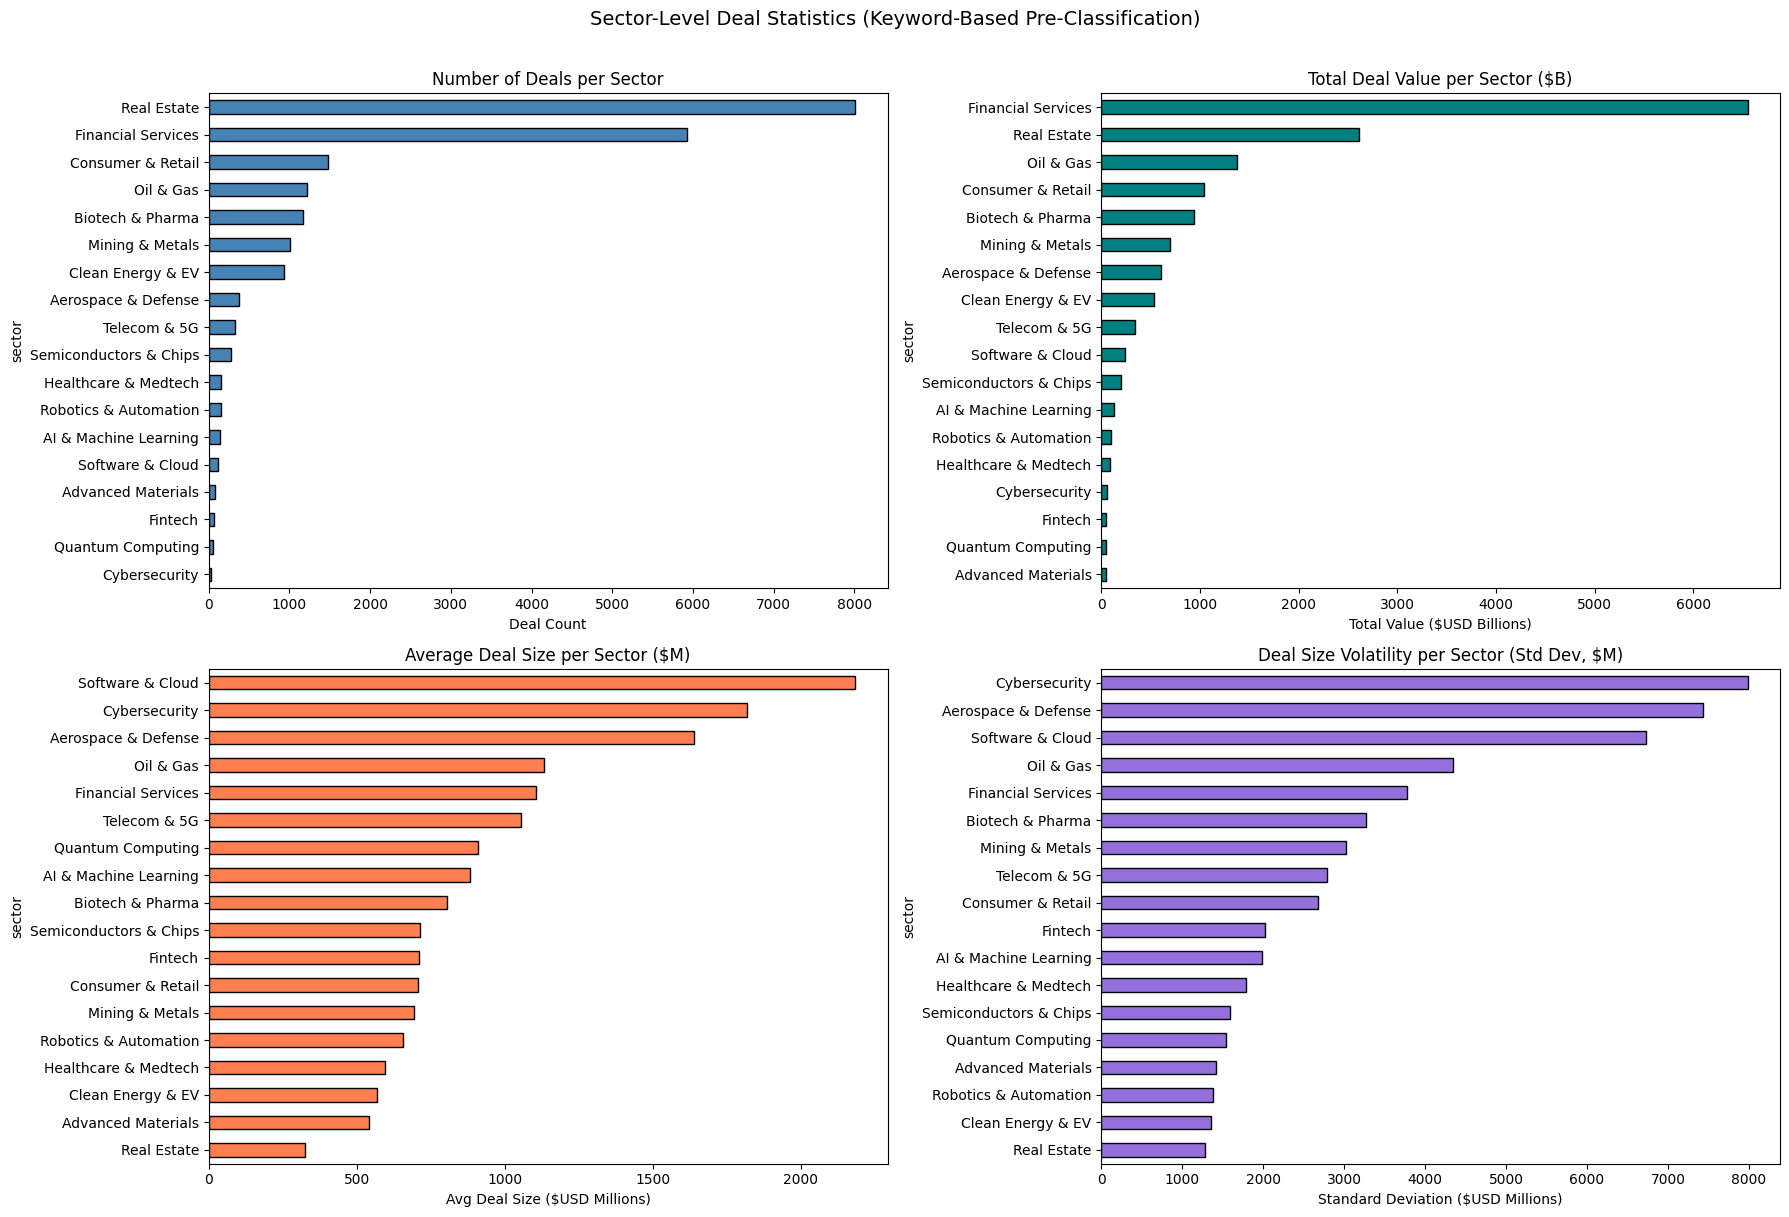

In [19]:
# --- Sector Visualizations ---
# Exclude 'Unclassified' for cleaner visuals
sector_stats_clean = sector_stats.drop('Unclassified', errors='ignore')

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Number of deals per sector
sector_stats_clean['nb_deals'].sort_values().plot(
    kind='barh', ax=axes[0, 0], color='steelblue', edgecolor='black')
axes[0, 0].set_title('Number of Deals per Sector')
axes[0, 0].set_xlabel('Deal Count')

# 2. Total deal value per sector ($B)
sector_stats_clean['total_value_B'].sort_values().plot(
    kind='barh', ax=axes[0, 1], color='teal', edgecolor='black')
axes[0, 1].set_title('Total Deal Value per Sector ($B)')
axes[0, 1].set_xlabel('Total Value ($USD Billions)')

# 3. Average deal size per sector ($M)
sector_stats_clean['mean_deal_M'].sort_values().plot(
    kind='barh', ax=axes[1, 0], color='coral', edgecolor='black')
axes[1, 0].set_title('Average Deal Size per Sector ($M)')
axes[1, 0].set_xlabel('Avg Deal Size ($USD Millions)')

# 4. Deal size dispersion (std dev) per sector
sector_stats_clean['std_deal_M'].sort_values().plot(
    kind='barh', ax=axes[1, 1], color='mediumpurple', edgecolor='black')
axes[1, 1].set_title('Deal Size Volatility per Sector (Std Dev, $M)')
axes[1, 1].set_xlabel('Standard Deviation ($USD Millions)')

plt.suptitle('Sector-Level Deal Statistics (Keyword-Based Pre-Classification)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [20]:
import plotly.express as px

# --- Treemap: Sector share of total deal value ---
# Gives an intuitive sense of which sectors dominate the M&A landscape
df_treemap = df[df['sector'] != 'Unclassified'].groupby('sector').agg(
    total_value=('value_usd_mm', 'sum'),
    deal_count=('transaction_id', 'count')
).reset_index()
df_treemap['avg_deal'] = (df_treemap['total_value'] / df_treemap['deal_count']).round(1)

fig = px.treemap(
    df_treemap,
    path=['sector'],
    values='total_value',
    color='deal_count',
    color_continuous_scale='Viridis',
    custom_data=['deal_count', 'avg_deal'],
    title='M&A Deal Volume by Sector (area = total value, color = deal count)'
)
fig.update_traces(
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Total Value: $%{value:,.0f}M<br>'
        'Deals: %{customdata[0]:,}<br>'
        'Avg Deal: $%{customdata[1]:,.0f}M'
        '<extra></extra>'
    ),
    textinfo='label+percent root'
)
fig.update_layout(height=500, margin=dict(t=50, l=10, r=10, b=10))
fig.show()

### 5.2 Interactive Buyer–Seller Network (colored by sector)

In [21]:
import networkx as nx
import plotly.graph_objects as go

# --- Determine primary sector for each buyer and seller ---
# A company's "primary sector" = the sector in which it has the most deal volume

def get_entity_sectors(df, col):
    """For each entity in `col`, find the sector with the highest total deal value."""
    entity_sectors = df.groupby([col, 'sector'])['value_usd_mm'].sum().reset_index()
    idx = entity_sectors.groupby(col)['value_usd_mm'].idxmax()
    return entity_sectors.loc[idx].set_index(col)['sector'].to_dict()

buyer_sectors = get_entity_sectors(df, 'buyer')
seller_sectors = get_entity_sectors(df, 'seller')

# --- Build the network from top players ---
top_n = 40
top_buyers = df.groupby('buyer')['value_usd_mm'].sum().nlargest(top_n).index
top_sellers = df.groupby('seller')['value_usd_mm'].sum().nlargest(top_n).index

df_net = df[df['buyer'].isin(top_buyers) | df['seller'].isin(top_sellers)].copy()
df_net = df_net.dropna(subset=['buyer', 'seller'])

edges = df_net.groupby(['buyer', 'seller']).agg(
    weight=('value_usd_mm', 'sum'),
    deal_count=('transaction_id', 'count'),
    sectors=('sector', lambda x: ', '.join(x.unique()))
).reset_index()

G = nx.Graph()
for _, row in edges.iterrows():
    G.add_edge(row['buyer'], row['seller'],
               weight=row['weight'], deals=row['deal_count'], sectors=row['sectors'])

# Node attributes
for node in G.nodes():
    is_buyer = node in set(df_net['buyer'].unique())
    is_seller = node in set(df_net['seller'].unique())
    G.nodes[node]['role'] = 'Both' if (is_buyer and is_seller) else ('Buyer' if is_buyer else 'Seller')
    G.nodes[node]['sector'] = buyer_sectors.get(node, seller_sectors.get(node, 'Unclassified'))
    val_b = df_net[df_net['buyer'] == node]['value_usd_mm'].sum()
    val_s = df_net[df_net['seller'] == node]['value_usd_mm'].sum()
    G.nodes[node]['total_value'] = val_b + val_s
    G.nodes[node]['deal_count'] = len(df_net[(df_net['buyer'] == node) | (df_net['seller'] == node)])

# Layout
pos = nx.spring_layout(G, k=3.0, iterations=150, seed=42)

# --- Build Plotly figure ---
# Sector color palette
all_sectors = list(SECTOR_KEYWORDS.keys()) + ['Unclassified']
sector_colors = {s: px.colors.qualitative.Dark24[i % len(px.colors.qualitative.Dark24)]
                 for i, s in enumerate(all_sectors)}

# Edge traces
edge_x, edge_y = [], []
edge_hover = []
for u, v, d in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    edge_x += [x0, x1, None]
    edge_y += [y0, y1, None]

edge_trace = go.Scatter(
    x=edge_x, y=edge_y, mode='lines',
    line=dict(width=0.5, color='rgba(150,150,150,0.3)'),
    hoverinfo='none'
)

# Node traces — one trace per sector for legend grouping
node_traces = []
for sector in all_sectors:
    sector_nodes = [n for n in G.nodes() if G.nodes[n]['sector'] == sector]
    if not sector_nodes:
        continue

    node_x = [pos[n][0] for n in sector_nodes]
    node_y = [pos[n][1] for n in sector_nodes]
    node_sizes = [max(np.log10(G.nodes[n]['total_value'] + 1) * 8, 8) for n in sector_nodes]

    hover_texts = []
    for n in sector_nodes:
        d = G.nodes[n]
        name = n[:60]
        hover_texts.append(
            f"<b>{name}</b><br>"
            f"Role: {d['role']}<br>"
            f"Sector: {d['sector']}<br>"
            f"Total Value: ${d['total_value']:,.0f}M<br>"
            f"Deals: {d['deal_count']}<br>"
            f"Connections: {G.degree(n)}"
        )

    # Marker symbol: circle for buyer, diamond for seller, star for both
    symbols = []
    for n in sector_nodes:
        role = G.nodes[n]['role']
        symbols.append('diamond' if role == 'Seller' else ('star' if role == 'Both' else 'circle'))

    trace = go.Scatter(
        x=node_x, y=node_y, mode='markers+text',
        marker=dict(
            size=node_sizes,
            color=sector_colors[sector],
            symbol=symbols,
            line=dict(width=1, color='white')
        ),
        text=[n[:20] if G.nodes[n]['total_value'] > np.percentile(
            [G.nodes[nn]['total_value'] for nn in G.nodes()], 90) else ''
            for n in sector_nodes],
        textposition='top center',
        textfont=dict(size=8),
        hovertext=hover_texts,
        hoverinfo='text',
        name=sector,
        legendgroup=sector,
        showlegend=True
    )
    node_traces.append(trace)

# Assemble figure
fig = go.Figure(data=[edge_trace] + node_traces)
fig.update_layout(
    title='Interactive M&A Network — Top Players by Deal Volume<br>'
          '<sub>Color = primary sector | Shape: ● buyer, ◆ seller, ★ both | Size = log deal volume</sub>',
    showlegend=True,
    legend=dict(title='Sector', font=dict(size=10), itemsizing='constant'),
    hovermode='closest',
    xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
    height=750,
    template='plotly_white',
    margin=dict(l=20, r=20, t=80, b=20)
)
fig.show()

print(f"Network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
print(f"\nSector distribution of network players:")
from collections import Counter
net_sectors = Counter(G.nodes[n]['sector'] for n in G.nodes())
for s, c in net_sectors.most_common():
    print(f"  {s:30s} {c} players")

Network: 623 nodes, 594 edges

Sector distribution of network players:
  Unclassified                   209 players
  Real Estate                    140 players
  Financial Services             129 players
  Biotech & Pharma               32 players
  Oil & Gas                      27 players
  Software & Cloud               17 players
  Consumer & Retail              16 players
  Clean Energy & EV              14 players
  Telecom & 5G                   10 players
  Mining & Metals                8 players
  Aerospace & Defense            7 players
  Semiconductors & Chips         4 players
  Cybersecurity                  3 players
  Quantum Computing              2 players
  AI & Machine Learning          2 players
  Healthcare & Medtech           1 players
  Advanced Materials             1 players
  Fintech                        1 players


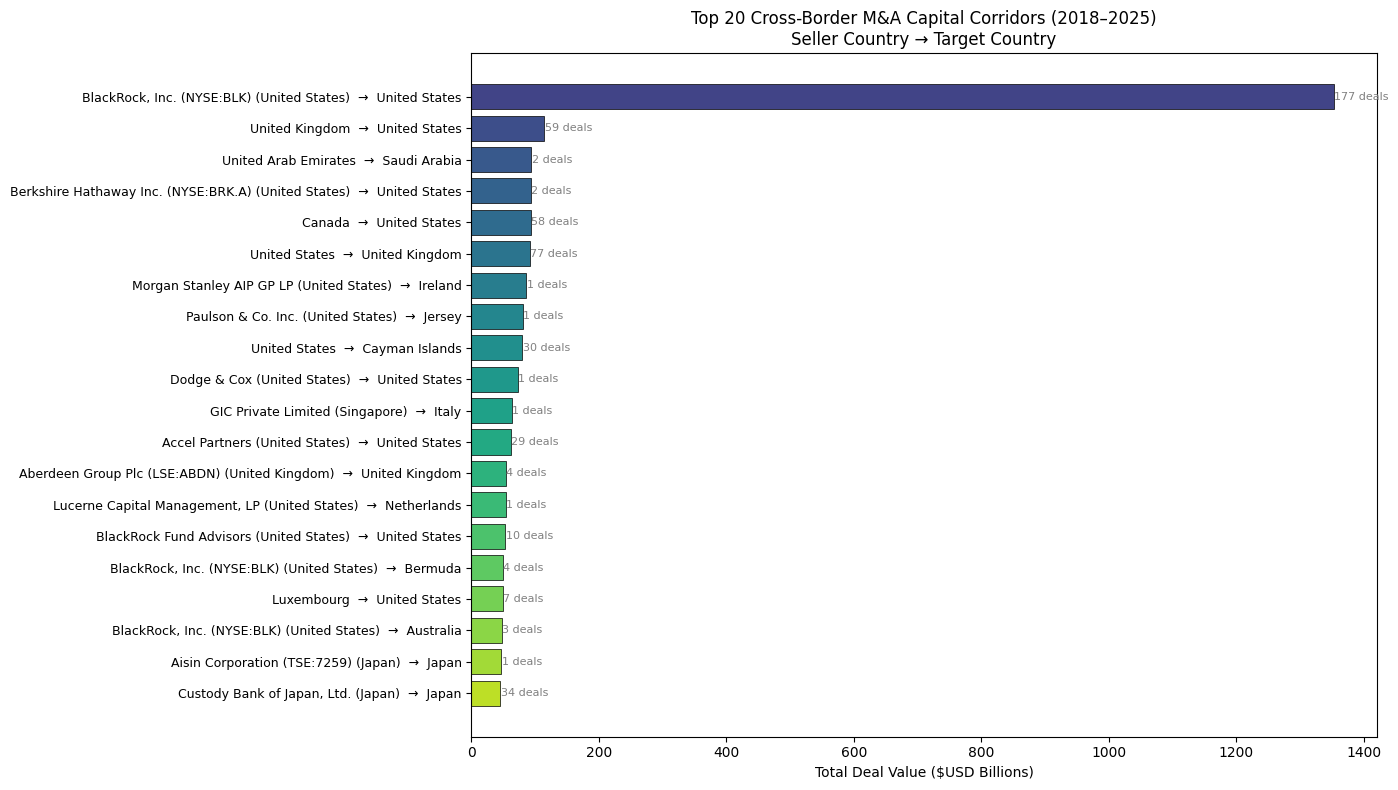

In [22]:
# --- 5b. Cross-Border Capital Flow — Top 15 Geographic Corridors ---
# Shows where M&A capital flows from (seller country) to (target country)
# Directly relevant to understanding deeptech investment corridors

df_geo = df.dropna(subset=['seller_country', 'target_country']).copy()

# For seller_country, some rows have multiple countries separated by ';'
# Take the first country for simplicity
df_geo['seller_country_clean'] = df_geo['seller_country'].str.split(';').str[0].str.strip()

# Aggregate capital flows between country pairs
flows = df_geo.groupby(['seller_country_clean', 'target_country']).agg(
    total_value=('value_usd_mm', 'sum'),
    deal_count=('transaction_id', 'count')
).reset_index()

# Filter to cross-border only (exclude same-country deals) and get top 20
flows_cross = flows[flows['seller_country_clean'] != flows['target_country']]
flows_top = flows_cross.nlargest(20, 'total_value')

# Plot as horizontal bar chart with flow labels
fig, ax = plt.subplots(figsize=(14, 8))
flow_labels = flows_top['seller_country_clean'] + '  →  ' + flows_top['target_country']
bars = ax.barh(
    range(len(flows_top)), 
    flows_top['total_value'] / 1000,
    color=plt.cm.viridis(np.linspace(0.2, 0.9, len(flows_top))),
    edgecolor='black', linewidth=0.5
)

ax.set_yticks(range(len(flows_top)))
ax.set_yticklabels(flow_labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel('Total Deal Value ($USD Billions)')
ax.set_title('Top 20 Cross-Border M&A Capital Corridors (2018–2025)\nSeller Country → Target Country')

# Annotate deal counts
for i, (val, count) in enumerate(zip(flows_top['total_value'], flows_top['deal_count'])):
    ax.text(val / 1000 + 0.5, i, f'{count} deals', va='center', fontsize=8, color='gray')

plt.tight_layout()
plt.show()

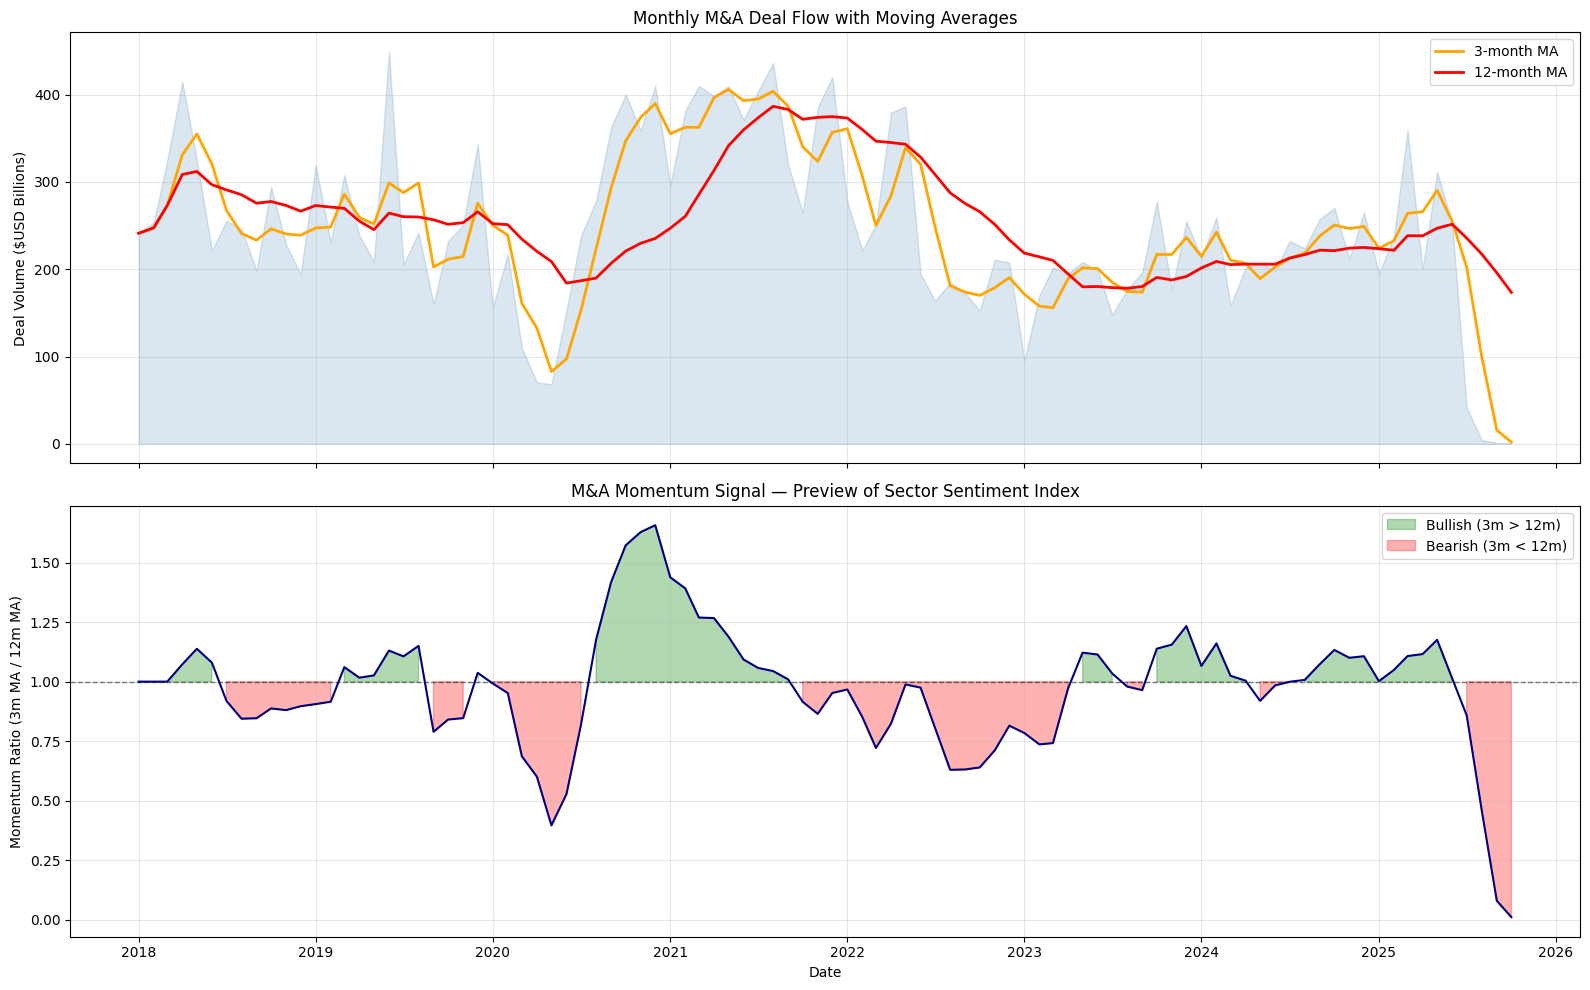

Current momentum ratio: 0.01
Peak momentum: 1.66 (2020-12)
Trough momentum: 0.01 (2025-10)


In [23]:
# --- 5c. Rolling Deal Momentum — Preview of the Sentiment Signal ---
# This previews what Step 3 of the project brief will produce:
# a rolling momentum indicator from deal flow data.

# Monthly aggregation
df['month'] = df['announced_date'].dt.to_period('M')
monthly = df.groupby('month').agg(
    deal_count=('transaction_id', 'count'),
    total_value=('value_usd_mm', 'sum')
).reset_index()
monthly['month_dt'] = monthly['month'].dt.to_timestamp()

# Rolling averages (3-month and 12-month) — mimics MACD-style signal
monthly['value_3m'] = monthly['total_value'].rolling(3, min_periods=1).mean()
monthly['value_12m'] = monthly['total_value'].rolling(12, min_periods=1).mean()

# Momentum signal: 3m / 12m ratio (>1 = accelerating, <1 = decelerating)
monthly['momentum'] = monthly['value_3m'] / monthly['value_12m']

fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# Top panel: deal flow with moving averages
axes[0].fill_between(monthly['month_dt'], monthly['total_value'] / 1000, alpha=0.2, color='steelblue')
axes[0].plot(monthly['month_dt'], monthly['value_3m'] / 1000, color='orange', linewidth=2, label='3-month MA')
axes[0].plot(monthly['month_dt'], monthly['value_12m'] / 1000, color='red', linewidth=2, label='12-month MA')
axes[0].set_ylabel('Deal Volume ($USD Billions)')
axes[0].set_title('Monthly M&A Deal Flow with Moving Averages')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Bottom panel: momentum ratio
axes[1].axhline(y=1.0, color='black', linestyle='--', linewidth=1, alpha=0.5)
axes[1].fill_between(monthly['month_dt'], monthly['momentum'], 1.0,
                      where=monthly['momentum'] >= 1.0, alpha=0.3, color='green', label='Bullish (3m > 12m)')
axes[1].fill_between(monthly['month_dt'], monthly['momentum'], 1.0,
                      where=monthly['momentum'] < 1.0, alpha=0.3, color='red', label='Bearish (3m < 12m)')
axes[1].plot(monthly['month_dt'], monthly['momentum'], color='navy', linewidth=1.5)
axes[1].set_ylabel('Momentum Ratio (3m MA / 12m MA)')
axes[1].set_xlabel('Date')
axes[1].set_title('M&A Momentum Signal — Preview of Sector Sentiment Index')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Current momentum ratio: {monthly['momentum'].iloc[-1]:.2f}")
print(f"Peak momentum: {monthly['momentum'].max():.2f} ({monthly.loc[monthly['momentum'].idxmax(), 'month']})")
print(f"Trough momentum: {monthly['momentum'].min():.2f} ({monthly.loc[monthly['momentum'].idxmin(), 'month']})")

/var/folders/7p/vbf4nhjx0p3dllb53kcxt4nh0000gn/T/ipykernel_22907/622059262.py:17: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  gini = 1 - 2 * np.trapz(cumulative, x)


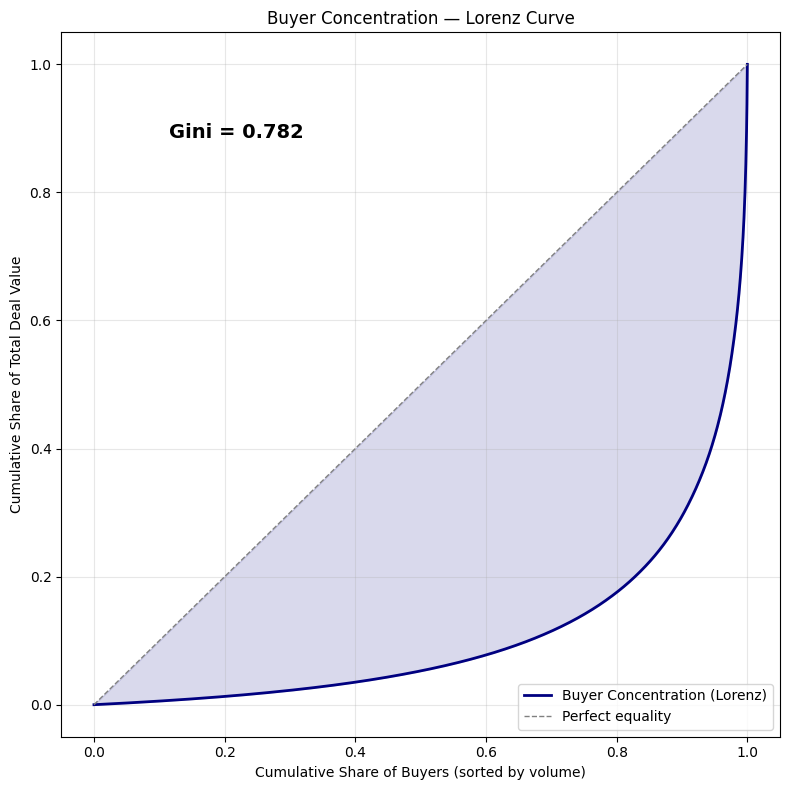

Total unique buyers: 22,649
Top 1% of buyers (226) account for 32.3% of total deal value
Top 5% of buyers (1,132) account for 58.1% of total deal value
Top 10 buyers account for 5.0% of total deal value


In [24]:
# --- 5d. Buyer Concentration — Lorenz Curve ---
# Shows how concentrated M&A activity is among buyers.
# If a small number of buyers dominate, sector-level signals may be driven by a few players.

buyer_totals = df.groupby('buyer')['value_usd_mm'].sum().sort_values().values
buyer_totals = buyer_totals[~np.isnan(buyer_totals)]
cumulative = np.cumsum(buyer_totals) / buyer_totals.sum()
n = len(buyer_totals)
x = np.arange(1, n + 1) / n

fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(x, cumulative, color='navy', linewidth=2, label='Buyer Concentration (Lorenz)')
ax.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Perfect equality')
ax.fill_between(x, cumulative, x, alpha=0.15, color='navy')

# Gini coefficient
gini = 1 - 2 * np.trapz(cumulative, x)
ax.text(0.15, 0.85, f'Gini = {gini:.3f}', fontsize=14, fontweight='bold', transform=ax.transAxes)

ax.set_xlabel('Cumulative Share of Buyers (sorted by volume)')
ax.set_ylabel('Cumulative Share of Total Deal Value')
ax.set_title('Buyer Concentration — Lorenz Curve')
ax.legend(loc='lower right')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Key concentration stats
top_1pct = max(int(n * 0.01), 1)
top_5pct = max(int(n * 0.05), 1)
top_1pct_value = buyer_totals[-top_1pct:].sum() / buyer_totals.sum() * 100
top_5pct_value = buyer_totals[-top_5pct:].sum() / buyer_totals.sum() * 100
top_10_value = buyer_totals[-10:].sum() / buyer_totals.sum() * 100

print(f"Total unique buyers: {n:,}")
print(f"Top 1% of buyers ({top_1pct:,}) account for {top_1pct_value:.1f}% of total deal value")
print(f"Top 5% of buyers ({top_5pct:,}) account for {top_5pct_value:.1f}% of total deal value")
print(f"Top 10 buyers account for {top_10_value:.1f}% of total deal value")

### 5.3 Per-Sector Deal Flow Time-Series (Step 2 Preview)
This is a direct preview of what the project's Step 2 deliverable will look like: **quarterly deal volume per sector**. Each line becomes a sector-level signal input for Step 3 (sentiment scoring).

In [25]:
# --- Per-sector quarterly deal flow (interactive) ---
# Exclude Unclassified and focus on deeptech-relevant sectors
deeptech_sectors = [
    'Quantum Computing', 'AI & Machine Learning', 'Semiconductors & Chips',
    'Cybersecurity', 'Aerospace & Defense', 'Robotics & Automation',
    'Biotech & Pharma', 'Advanced Materials', 'Clean Energy & EV',
    'Healthcare & Medtech', 'Software & Cloud'
]

df_dt = df[df['sector'].isin(deeptech_sectors)].copy()
df_dt['quarter'] = df_dt['announced_date'].dt.to_period('Q')

sector_quarterly = df_dt.groupby(['quarter', 'sector']).agg(
    total_value=('value_usd_mm', 'sum'),
    deal_count=('transaction_id', 'count')
).reset_index()
sector_quarterly['quarter_dt'] = sector_quarterly['quarter'].dt.to_timestamp()

# Interactive line chart — one line per sector
fig = px.line(
    sector_quarterly, x='quarter_dt', y='total_value', color='sector',
    title='Quarterly Deal Flow by Deeptech Sector (2018–2025)<br>'
          '<sub>Total transaction value per quarter — each line is a potential signal for Step 3</sub>',
    labels={'quarter_dt': 'Quarter', 'total_value': 'Deal Volume ($USD M)', 'sector': 'Sector'},
    hover_data={'deal_count': True, 'total_value': ':,.0f'}
)
fig.update_layout(
    height=600, template='plotly_white',
    legend=dict(font=dict(size=9)),
    hovermode='x unified'
)
fig.show()

# Also show the deal count version
fig2 = px.area(
    sector_quarterly, x='quarter_dt', y='deal_count', color='sector',
    title='Quarterly Deal Count by Deeptech Sector (stacked)<br>'
          '<sub>Shows sector activity regardless of deal size</sub>',
    labels={'quarter_dt': 'Quarter', 'deal_count': 'Number of Deals', 'sector': 'Sector'}
)
fig2.update_layout(height=500, template='plotly_white', legend=dict(font=dict(size=9)))
fig2.show()

### 5.4 Cross-Sector M&A Flow — Who Is Buying Whom?
Maps **buyer sector → target sector** to reveal consolidation patterns: are deeptech sectors being absorbed by financial services? Are tech sectors acquiring each other? Critical for understanding whether sector momentum is internally generated or driven by external capital.

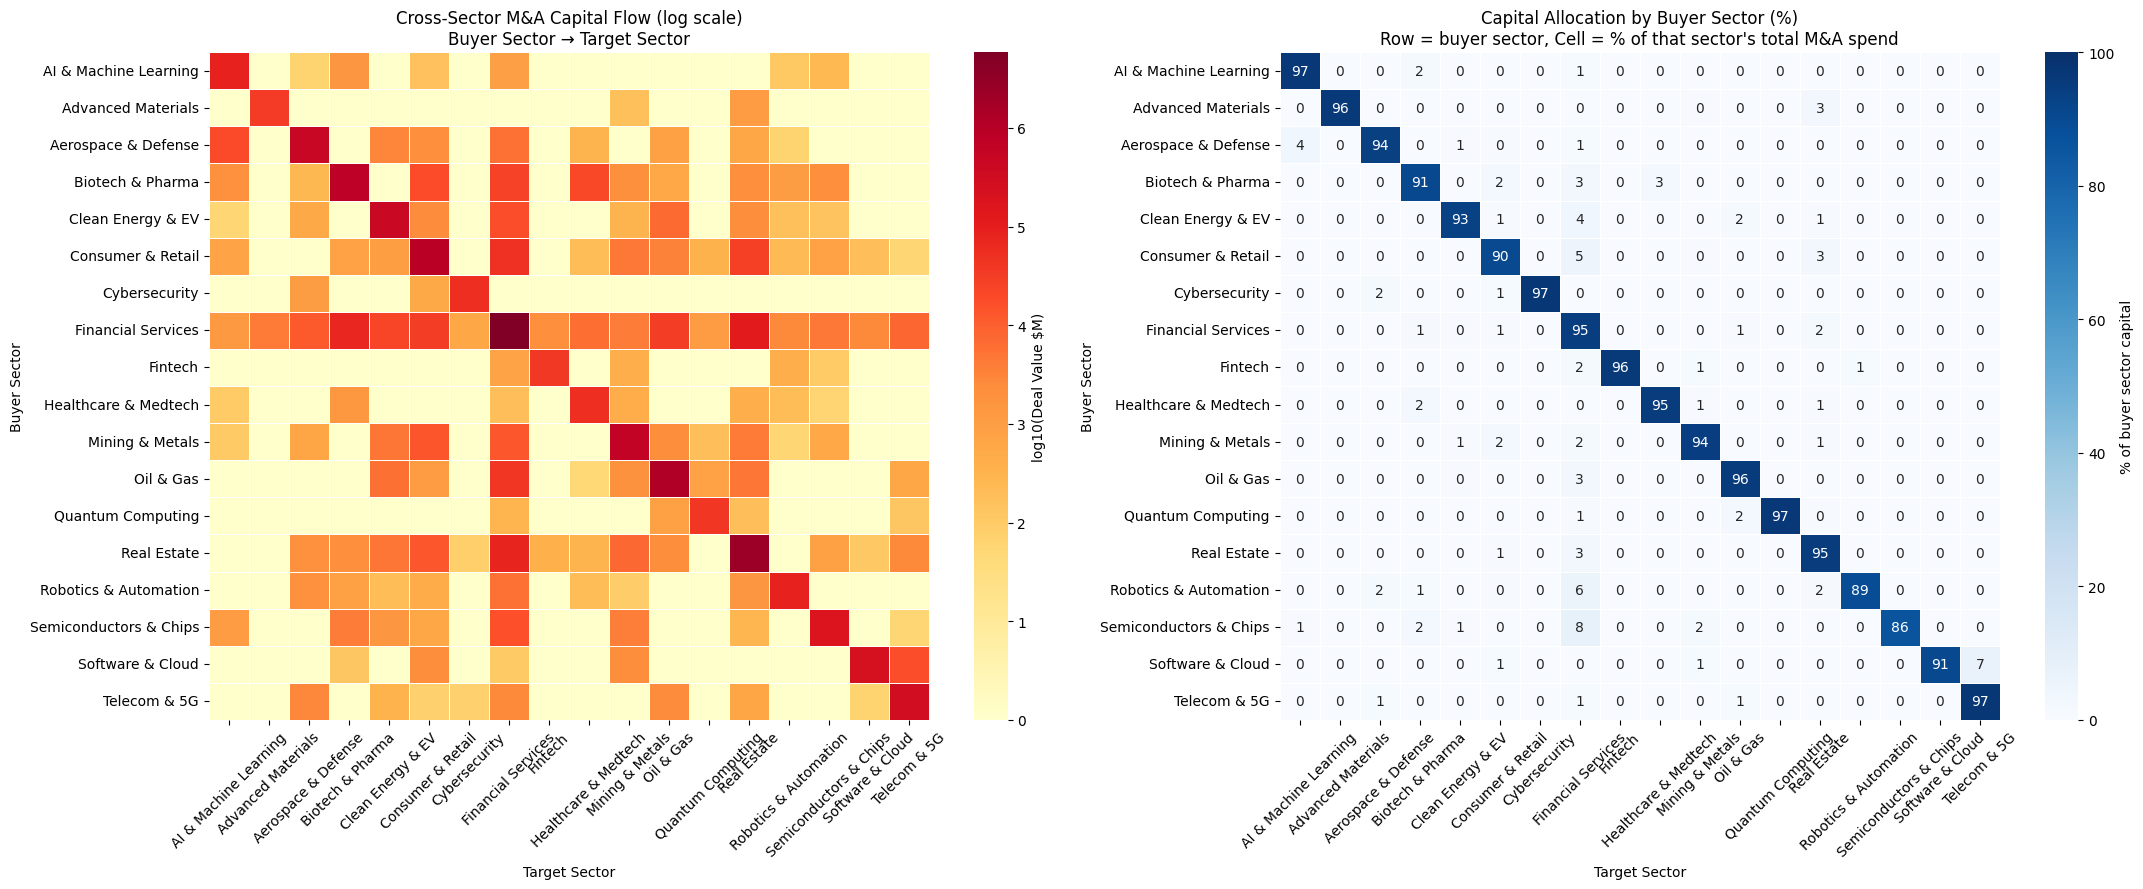

Intra-sector acquisition rates (diagonal):
  Cybersecurity                  97% of M&A capital stays within sector
  Telecom & 5G                   97% of M&A capital stays within sector
  AI & Machine Learning          97% of M&A capital stays within sector
  Quantum Computing              97% of M&A capital stays within sector
  Advanced Materials             96% of M&A capital stays within sector
  Fintech                        96% of M&A capital stays within sector
  Oil & Gas                      96% of M&A capital stays within sector
  Real Estate                    95% of M&A capital stays within sector
  Healthcare & Medtech           95% of M&A capital stays within sector
  Financial Services             95% of M&A capital stays within sector
  Mining & Metals                94% of M&A capital stays within sector
  Aerospace & Defense            94% of M&A capital stays within sector
  Clean Energy & EV              93% of M&A capital stays within sector
  Biotech & Pharma   

In [26]:
# --- Cross-sector acquisition heatmap ---
# Classify buyer sector from buyer's historical deals
df['buyer_sector'] = df['buyer'].map(buyer_sectors).fillna('Unclassified')

# Build buyer_sector → target_sector matrix (deal value)
cross = df.groupby(['buyer_sector', 'sector'])['value_usd_mm'].sum().reset_index()
cross.columns = ['buyer_sector', 'target_sector', 'total_value']

# Pivot to matrix (exclude Unclassified for clarity)
cross_filtered = cross[
    (~cross['buyer_sector'].isin(['Unclassified'])) &
    (~cross['target_sector'].isin(['Unclassified']))
]
matrix = cross_filtered.pivot_table(
    index='buyer_sector', columns='target_sector',
    values='total_value', fill_value=0
)

# Normalize per buyer row to show "where does each buyer-sector's capital go?"
matrix_pct = matrix.div(matrix.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(22, 9))

# Absolute values (log scale for visibility)
sns.heatmap(np.log10(matrix + 1), annot=False, cmap='YlOrRd', ax=axes[0],
            linewidths=0.5, cbar_kws={'label': 'log10(Deal Value $M)'})
axes[0].set_title('Cross-Sector M&A Capital Flow (log scale)\nBuyer Sector → Target Sector')
axes[0].set_xlabel('Target Sector')
axes[0].set_ylabel('Buyer Sector')
axes[0].tick_params(axis='x', rotation=45)
axes[0].tick_params(axis='y', rotation=0)

# Percentage view — where does each buyer sector deploy capital?
sns.heatmap(matrix_pct, annot=True, fmt='.0f', cmap='Blues', ax=axes[1],
            linewidths=0.5, cbar_kws={'label': '% of buyer sector capital'},
            vmin=0, vmax=100)
axes[1].set_title('Capital Allocation by Buyer Sector (%)\nRow = buyer sector, Cell = % of that sector\'s total M&A spend')
axes[1].set_xlabel('Target Sector')
axes[1].set_ylabel('Buyer Sector')
axes[1].tick_params(axis='x', rotation=45)
axes[1].tick_params(axis='y', rotation=0)

plt.tight_layout()
plt.show()

# Key insight: diagonal dominance = intra-sector consolidation
diag_pct = np.diag(matrix_pct.reindex(index=matrix_pct.columns, fill_value=0))
print("Intra-sector acquisition rates (diagonal):")
for sector, pct in sorted(zip(matrix_pct.columns, diag_pct), key=lambda x: -x[1]):
    if pct > 0:
        print(f"  {sector:30s} {pct:.0f}% of M&A capital stays within sector")

### 5.5 Sector Correlation Matrix
If two sectors' deal flows are highly correlated, their momentum signals are redundant — portfolio diversification (Step 4) should weight them accordingly. Low correlation sectors offer independent alpha.

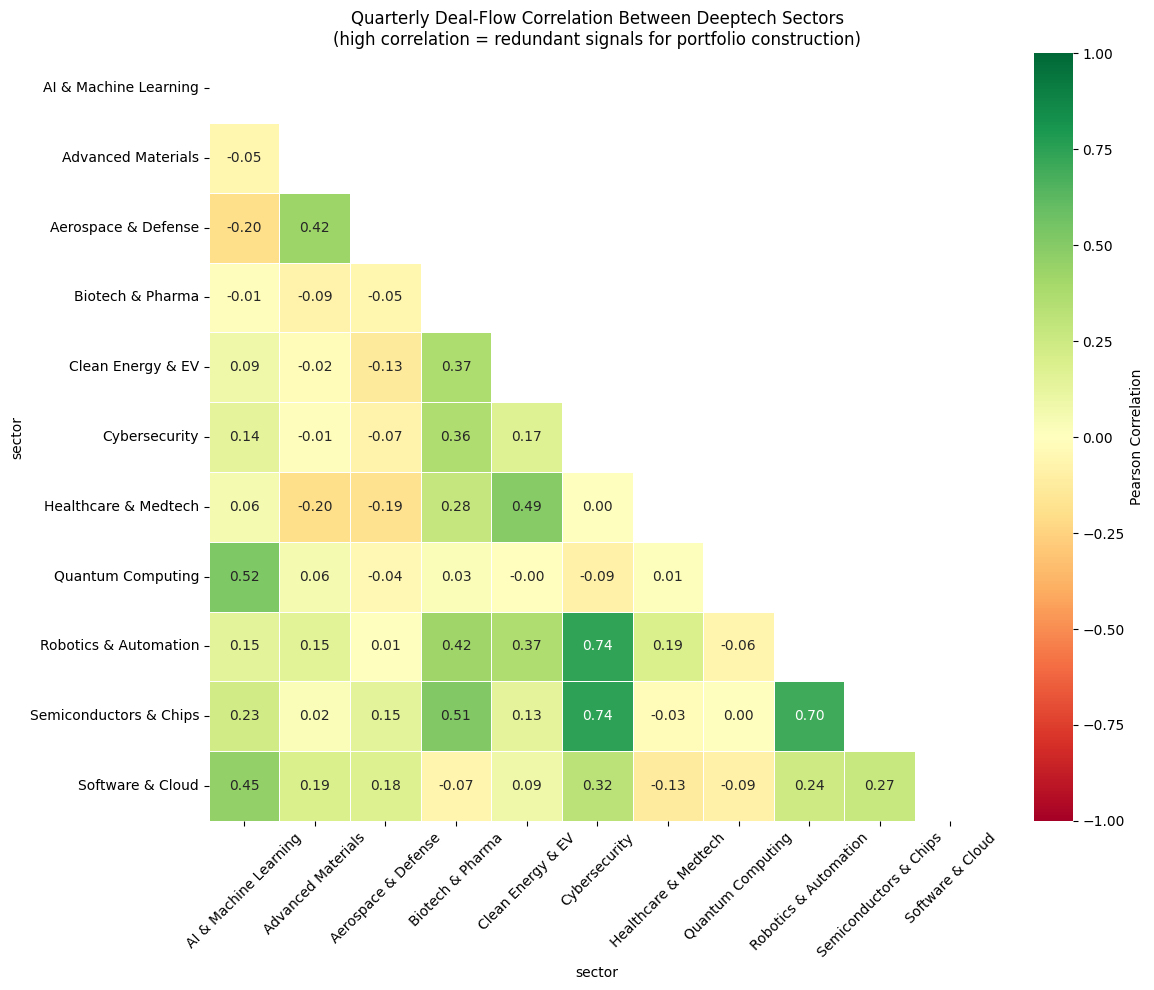

Top 5 most correlated sector pairs (potential signal redundancy):
  Cybersecurity                  ↔ Semiconductors & Chips          r = 0.743
  Cybersecurity                  ↔ Robotics & Automation           r = 0.738
  Robotics & Automation          ↔ Semiconductors & Chips          r = 0.696
  AI & Machine Learning          ↔ Quantum Computing               r = 0.517
  Biotech & Pharma               ↔ Semiconductors & Chips          r = 0.514

Top 5 least correlated pairs (independent signals for diversification):
  Healthcare & Medtech           ↔ Software & Cloud                r = -0.131
  Aerospace & Defense            ↔ Clean Energy & EV               r = -0.134
  Aerospace & Defense            ↔ Healthcare & Medtech            r = -0.186
  Advanced Materials             ↔ Healthcare & Medtech            r = -0.196
  AI & Machine Learning          ↔ Aerospace & Defense             r = -0.198


In [27]:
# --- Sector deal-flow correlation matrix (quarterly) ---
# Pivot: quarters as rows, sectors as columns, values = total deal value
sector_pivot = sector_quarterly.pivot_table(
    index='quarter_dt', columns='sector', values='total_value', fill_value=0
)

# Pearson correlation on the quarterly deal volumes
corr = sector_pivot.corr()

# Mask the upper triangle for cleaner visual
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn', center=0,
            vmin=-1, vmax=1, linewidths=0.5, ax=ax,
            cbar_kws={'label': 'Pearson Correlation'})
ax.set_title('Quarterly Deal-Flow Correlation Between Deeptech Sectors\n'
             '(high correlation = redundant signals for portfolio construction)')
ax.tick_params(axis='x', rotation=45)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

# Identify most and least correlated sector pairs
pairs = []
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        pairs.append((corr.columns[i], corr.columns[j], corr.iloc[i, j]))
pairs.sort(key=lambda x: x[2], reverse=True)

print("Top 5 most correlated sector pairs (potential signal redundancy):")
for s1, s2, r in pairs[:5]:
    print(f"  {s1:30s} ↔ {s2:30s}  r = {r:.3f}")
print("\nTop 5 least correlated pairs (independent signals for diversification):")
for s1, s2, r in pairs[-5:]:
    print(f"  {s1:30s} ↔ {s2:30s}  r = {r:.3f}")

### 5.6 Year-over-Year Sector Growth Rates
Identifies which deeptech sectors are **accelerating** vs **decelerating** — the raw signal behind momentum. Sectors with sustained positive YoY growth are candidates for bullish sentiment in Step 3.

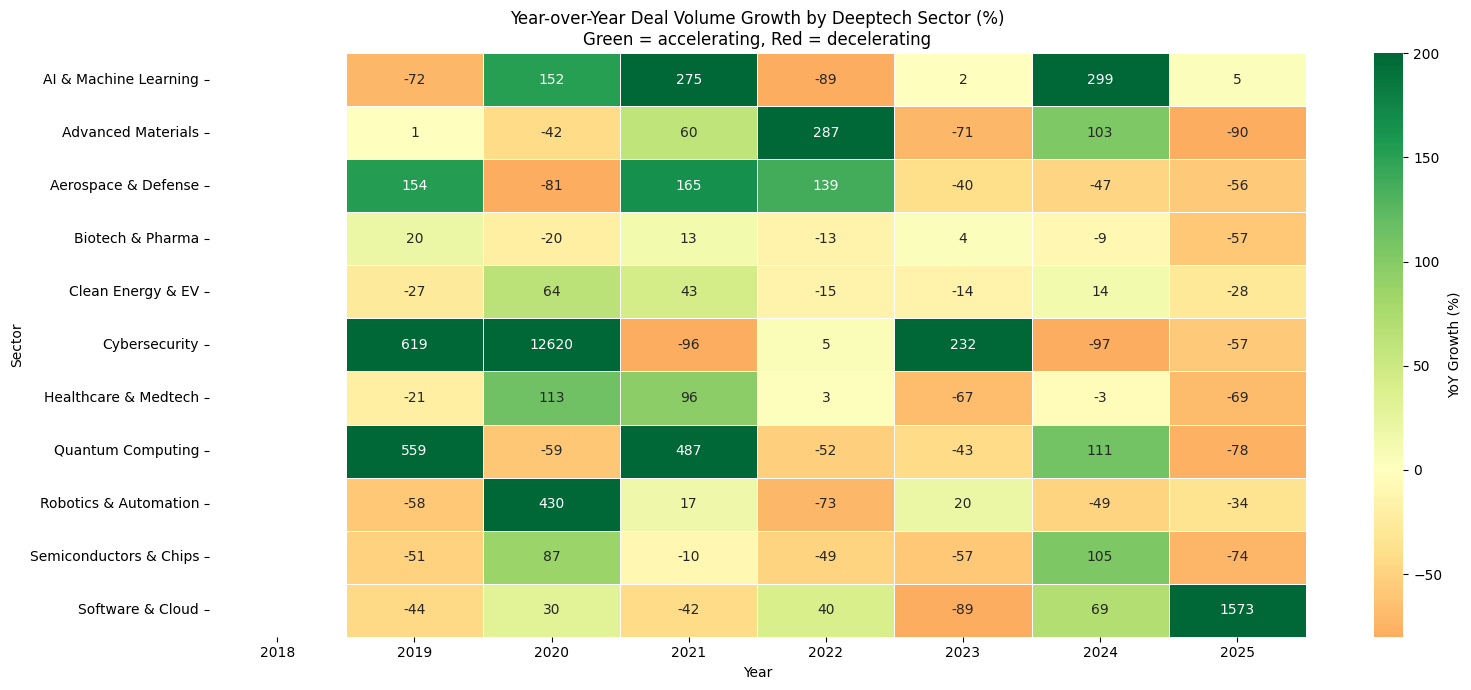

Compound Annual Growth Rate (CAGR) 2019–2025:
  Quantum Computing              ↓ -17.8%/yr  ($6.0B → $1.9B)
  AI & Machine Learning          ↑ +28.6%/yr  ($4.5B → $20.5B)
  Semiconductors & Chips         ↓ -24.0%/yr  ($22.5B → $4.4B)
  Cybersecurity                  ↓ -20.3%/yr  ($0.4B → $0.1B)
  Aerospace & Defense            ↓ -26.0%/yr  ($135.1B → $22.2B)
  Robotics & Automation          ↓ -6.0%/yr  ($4.9B → $3.4B)
  Biotech & Pharma               ↓ -17.6%/yr  ($152.0B → $47.7B)
  Advanced Materials             ↓ -23.5%/yr  ($4.3B → $0.9B)
  Clean Energy & EV              ↑ +5.7%/yr  ($39.5B → $55.0B)
  Healthcare & Medtech           ↓ -13.2%/yr  ($5.8B → $2.5B)
  Software & Cloud               ↑ +20.9%/yr  ($25.6B → $79.8B)


In [28]:
# --- YoY sector growth rates ---
df_dt['year'] = df_dt['announced_date'].dt.year
sector_yearly = df_dt.groupby(['year', 'sector'])['value_usd_mm'].sum().reset_index()
sector_yearly_pivot = sector_yearly.pivot_table(index='year', columns='sector', values='value_usd_mm', fill_value=0)

# YoY % change
yoy = sector_yearly_pivot.pct_change() * 100

# Heatmap of YoY growth rates
fig, ax = plt.subplots(figsize=(16, 7))
sns.heatmap(yoy.T, annot=True, fmt='.0f', cmap='RdYlGn', center=0,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'YoY Growth (%)'},
            vmin=-80, vmax=200)
ax.set_title('Year-over-Year Deal Volume Growth by Deeptech Sector (%)\n'
             'Green = accelerating, Red = decelerating')
ax.set_xlabel('Year')
ax.set_ylabel('Sector')
plt.tight_layout()
plt.show()

# CAGR (2019 to latest full year)
latest_year = int(df_dt['year'].max())
earliest_year = 2019  # skip 2018 which may be partial
n_years = latest_year - earliest_year

print(f"Compound Annual Growth Rate (CAGR) {earliest_year}–{latest_year}:")
for sector in deeptech_sectors:
    start = sector_yearly_pivot.loc[earliest_year, sector] if earliest_year in sector_yearly_pivot.index else 0
    end = sector_yearly_pivot.loc[latest_year, sector] if latest_year in sector_yearly_pivot.index else 0
    if start > 0 and end > 0 and n_years > 0:
        cagr = ((end / start) ** (1 / n_years) - 1) * 100
        arrow = '↑' if cagr > 0 else '↓'
        print(f"  {sector:30s} {arrow} {cagr:+.1f}%/yr  (${start/1000:.1f}B → ${end/1000:.1f}B)")
    else:
        print(f"  {sector:30s}   insufficient data")

### 5.7 Geographic Concentration per Deeptech Sector
Where is each deeptech sector's M&A activity concentrated? Reveals geographic risk (over-reliance on one region) and identifies regional hotspots for sector-specific signals.

In [29]:
# --- Geographic concentration per deeptech sector ---
df_dt_geo = df_dt.dropna(subset=['target_country'])
geo_sector = df_dt_geo.groupby(['sector', 'target_country'])['value_usd_mm'].sum().reset_index()

# For each sector, get top 5 countries by deal value
top_countries_per_sector = []
for sector in deeptech_sectors:
    s_data = geo_sector[geo_sector['sector'] == sector].nlargest(5, 'value_usd_mm')
    s_total = geo_sector[geo_sector['sector'] == sector]['value_usd_mm'].sum()
    s_data = s_data.copy()
    s_data['pct_of_sector'] = (s_data['value_usd_mm'] / s_total * 100).round(1)
    top_countries_per_sector.append(s_data)

geo_top = pd.concat(top_countries_per_sector)

# Interactive sunburst: sector → country
fig = px.sunburst(
    geo_top, path=['sector', 'target_country'], values='value_usd_mm',
    title='Deeptech M&A by Sector and Target Country<br>'
          '<sub>Inner ring = sector, outer ring = top 5 countries per sector</sub>',
    color='sector',
    color_discrete_sequence=px.colors.qualitative.Dark24
)
fig.update_layout(height=650, margin=dict(t=60, l=10, r=10, b=10))
fig.update_traces(
    hovertemplate='<b>%{label}</b><br>Deal Value: $%{value:,.0f}M<extra></extra>'
)
fig.show()

# Herfindahl-Hirschman Index (HHI) per sector — measures geographic concentration
# HHI > 2500 = highly concentrated, 1500-2500 = moderate, < 1500 = competitive
print("Geographic Concentration (HHI) per Deeptech Sector:")
print("  (HHI > 2500 = highly concentrated in few countries)")
print()
for sector in deeptech_sectors:
    s_data = geo_sector[geo_sector['sector'] == sector]
    s_total = s_data['value_usd_mm'].sum()
    if s_total > 0:
        shares = (s_data['value_usd_mm'] / s_total * 100)
        hhi = (shares ** 2).sum()
        top_country = s_data.nlargest(1, 'value_usd_mm')['target_country'].values[0]
        top_share = shares.max()
        level = 'HIGH' if hhi > 2500 else ('MOD' if hhi > 1500 else 'LOW')
        print(f"  {sector:30s} HHI={hhi:6,.0f} [{level:4s}]  Top: {top_country} ({top_share:.0f}%)")

Geographic Concentration (HHI) per Deeptech Sector:
  (HHI > 2500 = highly concentrated in few countries)

  Quantum Computing              HHI= 3,010 [HIGH]  Top: United States (47%)
  AI & Machine Learning          HHI= 3,523 [HIGH]  Top: United States (58%)
  Semiconductors & Chips         HHI= 2,378 [MOD ]  Top: United States (36%)
  Cybersecurity                  HHI= 6,838 [HIGH]  Top: Bermuda (81%)
  Aerospace & Defense            HHI= 4,105 [HIGH]  Top: United States (62%)
  Robotics & Automation          HHI= 1,880 [MOD ]  Top: United States (35%)
  Biotech & Pharma               HHI= 3,117 [HIGH]  Top: United States (54%)
  Advanced Materials             HHI= 2,107 [MOD ]  Top: China (33%)
  Clean Energy & EV              HHI= 2,277 [MOD ]  Top: United States (45%)
  Healthcare & Medtech           HHI= 4,062 [HIGH]  Top: United States (61%)
  Software & Cloud               HHI= 8,643 [HIGH]  Top: United States (93%)


### 5.8 Sector Seasonality & Deal Completion Analysis
Two dimensions of signal quality:
- **Seasonality**: Are there recurring monthly patterns? If deal flow is seasonal, the momentum signal must be deseasonalized.
- **Completion rate**: What % of announced deals actually close? Low completion rates make the sector signal noisier.

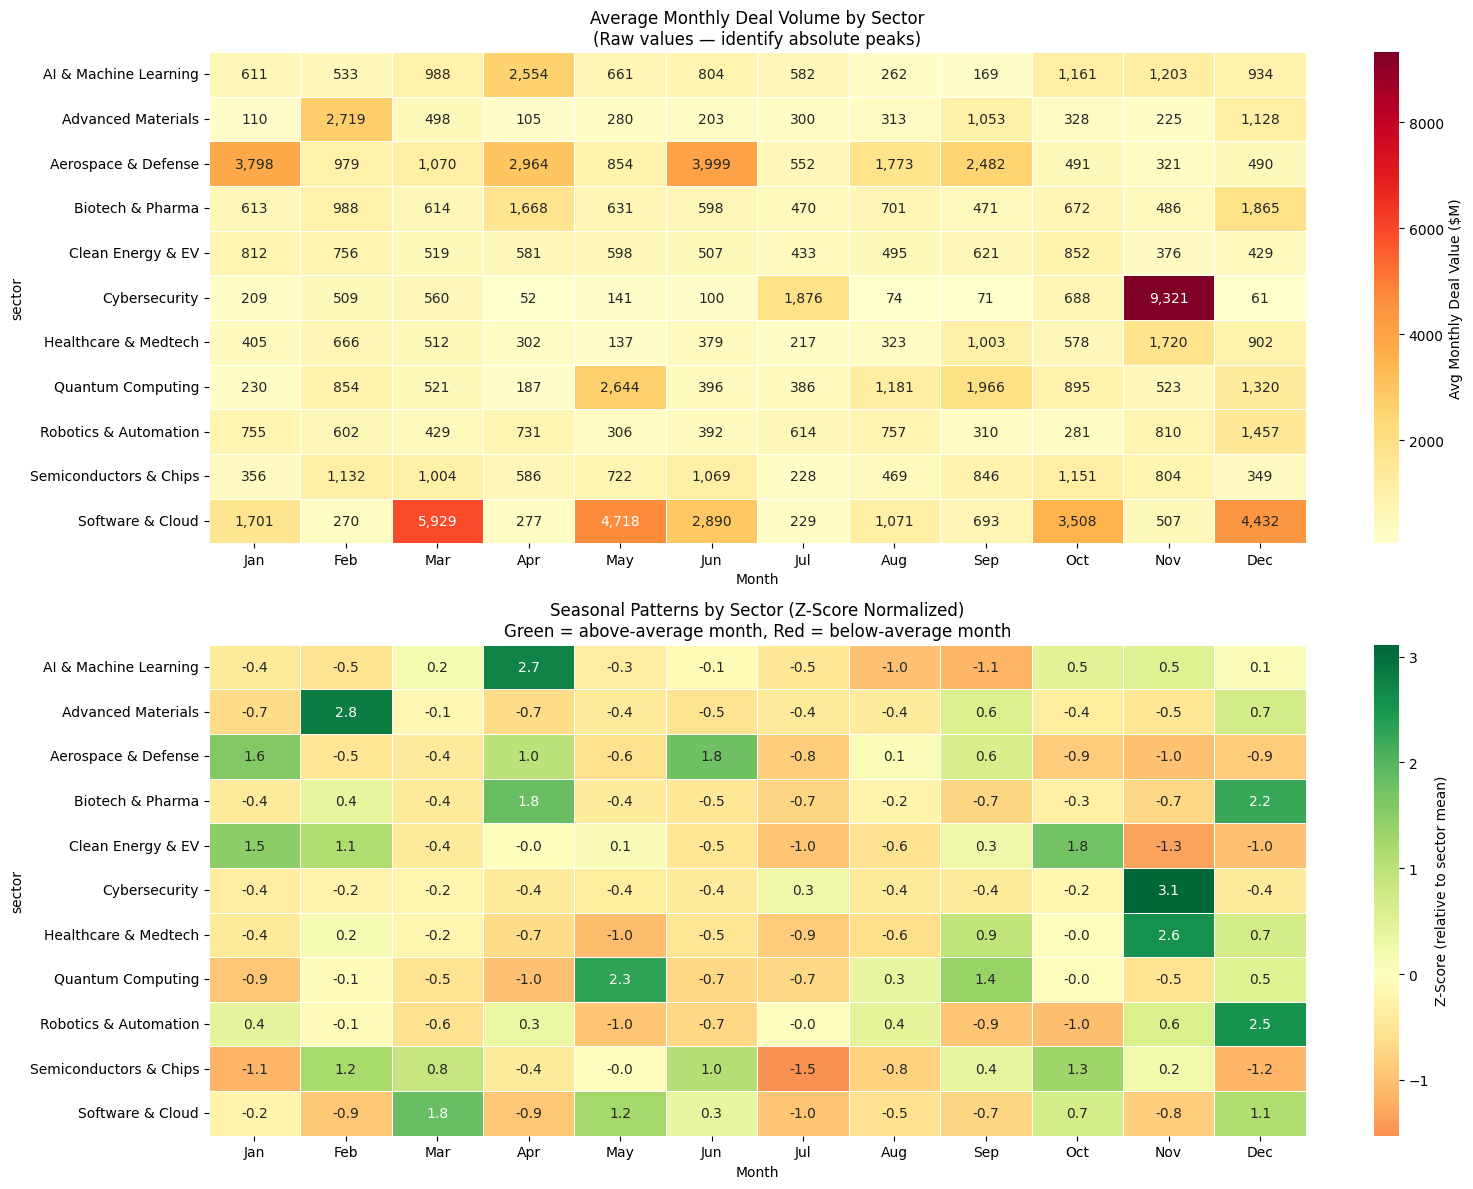

In [30]:
# --- Seasonality heatmap: month × sector ---
df_dt['month_num'] = df_dt['announced_date'].dt.month
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

seasonality = df_dt.groupby(['month_num', 'sector'])['value_usd_mm'].mean().reset_index()
season_pivot = seasonality.pivot_table(index='sector', columns='month_num', values='value_usd_mm', fill_value=0)

# Normalize per sector (z-score across months) to show relative seasonal patterns
season_zscore = season_pivot.sub(season_pivot.mean(axis=1), axis=0).div(season_pivot.std(axis=1), axis=0)

fig, axes = plt.subplots(2, 1, figsize=(16, 12))

# Raw average deal value per month
sns.heatmap(season_pivot, annot=True, fmt=',.0f', cmap='YlOrRd', ax=axes[0],
            linewidths=0.5, xticklabels=month_names,
            cbar_kws={'label': 'Avg Monthly Deal Value ($M)'})
axes[0].set_title('Average Monthly Deal Volume by Sector\n(Raw values — identify absolute peaks)')
axes[0].set_xlabel('Month')

# Z-scored seasonality — reveals relative monthly patterns per sector
sns.heatmap(season_zscore, annot=True, fmt='.1f', cmap='RdYlGn', center=0, ax=axes[1],
            linewidths=0.5, xticklabels=month_names,
            cbar_kws={'label': 'Z-Score (relative to sector mean)'})
axes[1].set_title('Seasonal Patterns by Sector (Z-Score Normalized)\n'
                   'Green = above-average month, Red = below-average month')
axes[1].set_xlabel('Month')

plt.tight_layout()
plt.show()

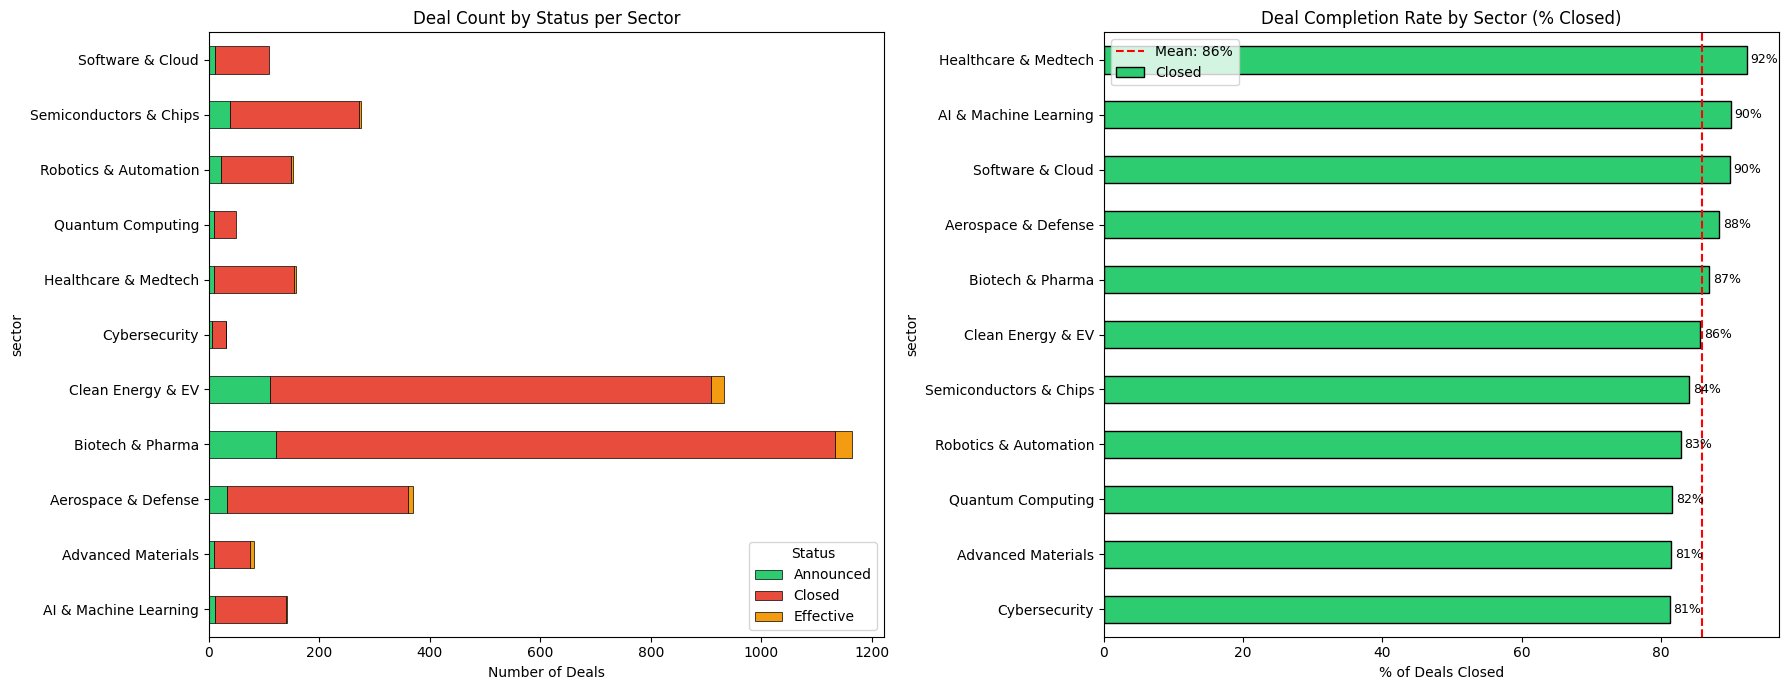

Signal reliability insight:
  Sectors with low completion rates have noisier momentum signals
  because announced-but-not-closed deals inflate capital flow metrics.


In [31]:
# --- Deal completion rate by sector ---
# 'status' column: Closed, Announced, Withdrawn, etc.
# Only closed deals represent realized capital flow — high Announced/Withdrawn rates add noise

completion = df_dt.groupby(['sector', 'status']).agg(
    deal_count=('transaction_id', 'count'),
    total_value=('value_usd_mm', 'sum')
).reset_index()

# Pivot for stacked bar
completion_pivot = completion.pivot_table(
    index='sector', columns='status', values='deal_count', fill_value=0
)
completion_pct = completion_pivot.div(completion_pivot.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Stacked bar: deal count by status
completion_pivot.plot(kind='barh', stacked=True, ax=axes[0],
                       color=['#2ecc71', '#e74c3c', '#f39c12', '#95a5a6'],
                       edgecolor='black', linewidth=0.5)
axes[0].set_title('Deal Count by Status per Sector')
axes[0].set_xlabel('Number of Deals')
axes[0].legend(title='Status', loc='lower right')

# Completion rate (% Closed)
if 'Closed' in completion_pct.columns:
    closed_pct = completion_pct['Closed'].sort_values()
    closed_pct.plot(kind='barh', ax=axes[1], color='#2ecc71', edgecolor='black')
    axes[1].set_title('Deal Completion Rate by Sector (% Closed)')
    axes[1].set_xlabel('% of Deals Closed')
    axes[1].axvline(x=closed_pct.mean(), color='red', linestyle='--', label=f'Mean: {closed_pct.mean():.0f}%')
    axes[1].legend()

    # Annotate
    for i, (sector, pct) in enumerate(closed_pct.items()):
        axes[1].text(pct + 0.5, i, f'{pct:.0f}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("Signal reliability insight:")
print("  Sectors with low completion rates have noisier momentum signals")
print("  because announced-but-not-closed deals inflate capital flow metrics.")

### 5.9 Mega-Deal Sensitivity Analysis
Large single transactions can dominate a sector's quarterly signal. This analysis quantifies **how much each sector's signal depends on its top deals** — high sensitivity means the momentum signal is fragile and may need winsorization or median-based aggregation.

Mega-Deal Sensitivity per Sector:
(top5_pct = % of total sector value from 5 largest deals)

  Cybersecurity                  Top5= 91.7%  Top1= 78.0%  Skew=  5.6  [FRAGILE]
  Software & Cloud               Top5= 63.5%  Top1= 15.4%  Skew=  4.1  [FRAGILE]
  Advanced Materials             Top5= 54.5%  Top1= 25.0%  Skew=  5.8  [FRAGILE]
  Quantum Computing              Top5= 49.4%  Top1= 20.6%  Skew=  3.7  [MODERATE]
  Aerospace & Defense            Top5= 46.0%  Top1= 15.3%  Skew=  9.4  [MODERATE]
  Healthcare & Medtech           Top5= 42.9%  Top1= 20.3%  Skew=  8.1  [MODERATE]
  Robotics & Automation          Top5= 33.1%  Top1= 12.2%  Skew=  5.1  [MODERATE]
  AI & Machine Learning          Top5= 33.0%  Top1= 15.9%  Skew=  6.8  [MODERATE]
  Semiconductors & Chips         Top5= 24.6%  Top1=  6.6%  Skew=  4.6  [ROBUST]
  Biotech & Pharma               Top5= 21.6%  Top1=  8.6%  Skew= 16.1  [ROBUST]
  Clean Energy & EV              Top5= 11.5%  Top1=  5.5%  Skew= 11.8  [ROBUST]


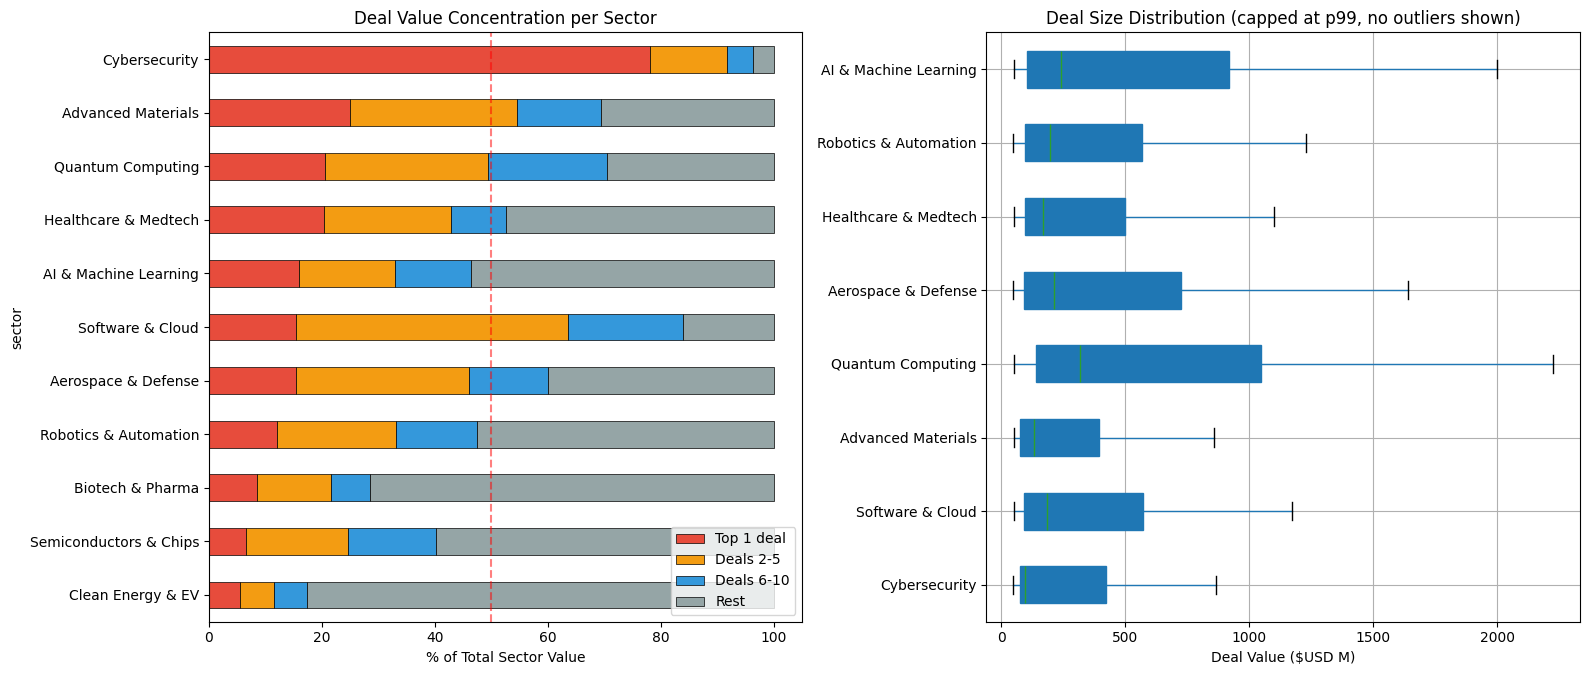


Implication for signal construction:
  FRAGILE sectors: use median aggregation or winsorize before computing momentum.
  ROBUST sectors: mean aggregation is safe; signal less sensitive to individual deals.


In [32]:
# --- Mega-deal sensitivity: how much do top 5 deals drive each sector's signal? ---
mega_analysis = []
for sector in deeptech_sectors:
    s_data = df_dt[df_dt['sector'] == sector]['value_usd_mm'].sort_values(ascending=False)
    total = s_data.sum()
    n = len(s_data)
    if total > 0 and n > 0:
        top1_pct = s_data.iloc[0] / total * 100 if n >= 1 else 0
        top5_pct = s_data.iloc[:5].sum() / total * 100 if n >= 5 else s_data.sum() / total * 100
        top10_pct = s_data.iloc[:10].sum() / total * 100 if n >= 10 else s_data.sum() / total * 100
        median = s_data.median()
        p99 = s_data.quantile(0.99)
        mega_analysis.append({
            'sector': sector,
            'total_deals': n,
            'total_value_B': total / 1000,
            'top1_pct': top1_pct,
            'top5_pct': top5_pct,
            'top10_pct': top10_pct,
            'median_deal_M': median,
            'p99_deal_M': p99,
            'skewness': s_data.skew(),
        })

mega_df = pd.DataFrame(mega_analysis).set_index('sector').sort_values('top5_pct', ascending=False)

# Display table
print("Mega-Deal Sensitivity per Sector:")
print("(top5_pct = % of total sector value from 5 largest deals)\n")
for _, row in mega_df.iterrows():
    sensitivity = 'FRAGILE' if row['top5_pct'] > 50 else ('MODERATE' if row['top5_pct'] > 30 else 'ROBUST')
    print(f"  {row.name:30s} Top5={row['top5_pct']:5.1f}%  Top1={row['top1_pct']:5.1f}%  "
          f"Skew={row['skewness']:5.1f}  [{sensitivity}]")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: stacked bar showing top1/top5/top10/rest concentration
mega_df_viz = mega_df[['top1_pct', 'top5_pct', 'top10_pct']].copy()
mega_df_viz['top2_5_pct'] = mega_df_viz['top5_pct'] - mega_df_viz['top1_pct']
mega_df_viz['top6_10_pct'] = mega_df_viz['top10_pct'] - mega_df_viz['top5_pct']
mega_df_viz['rest_pct'] = 100 - mega_df_viz['top10_pct']

mega_df_viz[['top1_pct', 'top2_5_pct', 'top6_10_pct', 'rest_pct']].sort_values('top1_pct').plot(
    kind='barh', stacked=True, ax=axes[0],
    color=['#e74c3c', '#f39c12', '#3498db', '#95a5a6'],
    edgecolor='black', linewidth=0.5
)
axes[0].set_title('Deal Value Concentration per Sector')
axes[0].set_xlabel('% of Total Sector Value')
axes[0].legend(['Top 1 deal', 'Deals 2-5', 'Deals 6-10', 'Rest'], loc='lower right')
axes[0].axvline(x=50, color='red', linestyle='--', alpha=0.5)

# Right: violin plot showing deal size distribution per sector
df_dt_violin = df_dt[df_dt['sector'].isin(
    mega_df.index[:8]  # top 8 sectors by sensitivity
)].copy()

# Cap at 99th percentile for visibility
cap = df_dt_violin['value_usd_mm'].quantile(0.99)
df_dt_violin['value_capped'] = df_dt_violin['value_usd_mm'].clip(upper=cap)

# Box plot instead of violin for more stats
sector_order = mega_df.index[:8].tolist()
df_dt_violin['sector'] = pd.Categorical(df_dt_violin['sector'], categories=sector_order, ordered=True)
df_dt_violin.boxplot(column='value_capped', by='sector', ax=axes[1], vert=False,
                      patch_artist=True, showfliers=False)
axes[1].set_title('Deal Size Distribution (capped at p99, no outliers shown)')
axes[1].set_xlabel('Deal Value ($USD M)')
axes[1].set_ylabel('')
fig.suptitle('')  # Remove auto-title from boxplot

plt.tight_layout()
plt.show()

print("\nImplication for signal construction:")
print("  FRAGILE sectors: use median aggregation or winsorize before computing momentum.")
print("  ROBUST sectors: mean aggregation is safe; signal less sensitive to individual deals.")